# Investor Attention and Lead–Lag Networks in U.S. Equities

## Research Question:
**Can investor attention be used to improve the predictive performance of lead–lag relationships between U.S. stocks within the same industry?**

This notebook constructs and compares price-only and attention-informed lead–lag trading strategies using Bloomberg daily data for 50 U.S. equities from 1 January 2020 to 30 September 2026.

It documents data processing, network construction, backtesting, robustness checks and risk evaluation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import time

DATA_PATH = Path("data/bloomberg_data.xlsx")

print("Setup complete.")

Setup complete.


## 1. Data Pipeline

### 1.1 Data Acquisition

Daily Bloomberg data was exported using Excel Spreadsheet Builder. The following cells load the submitted snapshot and extract the four fields: 
- `PX_LAST`
- `NEWS_PUBLICATION_COUNT`
- `PX_VOLUME`
- `TOT_RETURN_INDEX_GROSS_DVDS`

In [2]:
excel_file = pd.ExcelFile(DATA_PATH)

print("Sheets:")
print(excel_file.sheet_names)

Sheets:
['Prices', 'News_Attention', 'Tickers', 'Final_Data', 'Sheet1']


In [3]:
raw = pd.read_excel(
    DATA_PATH,
    sheet_name="Final_Data",
    header=None
)

print("Shape:", raw.shape)
display(raw.iloc[:10, :12])

Shape: (1767, 201)


,0,1,2,3,4,5,6,7,8,9,10,11
0,Start Date,2020-01-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,End Date,2026-09-30 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,JPM US Equity,NaN,NaN,NaN,BAC US Equity,NaN,NaN,NaN,WFC US Equity,NaN,NaN
4,NaN,Last Price,News Publication Count,Volume,Total Return Index (Gross Dividends),Last Price,News Publication Count,Volume,Total Return Index (Gross Dividends),Last Price,News Publication Count,Volume
5,Dates,PX_LAST,NEWS_PUBLICATION_COUNT,PX_VOLUME,TOT_RETURN_INDEX_GROSS_DVDS,PX_LAST,NEWS_PUBLICATION_COUNT,PX_VOLUME,TOT_RETURN_INDEX_GROSS_DVDS,PX_LAST,NEWS_PUBLICATION_COUNT,PX_VOLUME
6,2020-01-01 00:00:00,NaN,822,NaN,NaN,NaN,161,NaN,NaN,NaN,276,NaN
7,2020-01-02 00:00:00,141.09,482,10811019,141.09,35.64,176,37643855,35.64,53.75,334,16806063
8,2020-01-03 00:00:00,138.34,1637,10387518,139.24,34.9,308,50763659,34.9,53.42,560,15609670
9,2020-01-06 00:00:00,138.23,647,10266522,139.1293,34.85,263,42233299,34.85,53.1,396,13200655


In [4]:
# Bloomberg's actual observations begin on row 6
data = raw.iloc[6:].copy()

# First column contains dates.
# Handle both normal dates and Excel serial date numbers.
raw_dates = data.iloc[:, 0]

dates = raw_dates.apply(
    lambda value: (
        pd.to_datetime(value, unit="D", origin="1899-12-30")
        if isinstance(value, (int, float, np.integer, np.floating))
        else pd.to_datetime(value)
    )
)

dates = pd.DatetimeIndex(dates)

# Validate the imported dates before creating the data tables.
assert dates.notna().all(), "Some dates could not be parsed"
assert dates.is_monotonic_increasing, "Dates are not chronological"
assert dates.is_unique, "Duplicate dates detected"

print("Date range:", dates.min(), "to", dates.max())
print("Dates parsed correctly:", len(dates))

prices = pd.DataFrame(index=dates)
news = pd.DataFrame(index=dates)
volume = pd.DataFrame(index=dates)
total_return = pd.DataFrame(index=dates)

# Every company occupies four consecutive columns
for col in range(1, raw.shape[1], 4):

    ticker = raw.iloc[3, col]
    
    # Convert "JPM US Equity" -> "JPM"
    ticker = str(ticker).replace(" US Equity", "")

    prices[ticker] = pd.to_numeric(data.iloc[:, col].values, errors="coerce")
    news[ticker] = pd.to_numeric(data.iloc[:, col + 1].values, errors="coerce")
    volume[ticker] = pd.to_numeric(data.iloc[:, col + 2].values, errors="coerce")
    total_return[ticker] = pd.to_numeric(
        data.iloc[:, col + 3].values,
        errors="coerce"
    )

print("Prices:", prices.shape)
print("News:", news.shape)
print("Volume:", volume.shape)
print("Total return:", total_return.shape)

display(prices.head())

Date range: 2020-01-01 00:00:00 to 2026-09-30 00:00:00
Dates parsed correctly: 1761
Prices: (1761, 50)
News: (1761, 50)
Volume: (1761, 50)
Total return: (1761, 50)


,JPM,BAC,WFC,C,USB,PNC,TFC,BNY,STT,GS,...,XOM,CVX,COP,EOG,SLB,MPC,PSX,VLO,OXY,HAL
0,,,,,,,,,,,,,,,,,,,,,
2020-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-02,141.09,35.64,53.75,81.23,59.20,160.37,56.67,50.92,80.76,234.32,...,70.90,121.43,65.46,84.14,40.17,61.91,112.20,95.13,42.58,24.68
2020-01-03,138.34,34.90,53.42,79.70,58.51,158.83,56.20,50.27,79.57,231.58,...,70.33,121.01,65.70,84.99,40.56,58.23,108.49,91.52,43.61,24.76
2020-01-06,138.23,34.85,53.10,79.45,57.71,158.51,55.73,50.74,80.79,233.95,...,70.87,120.60,66.48,88.44,40.82,58.22,107.81,91.53,45.05,25.39
2020-01-07,135.88,34.62,52.66,78.76,57.16,157.26,55.49,51.25,81.91,235.49,...,70.29,119.06,66.48,89.29,40.61,59.14,108.14,92.73,45.27,24.67


In [5]:
# Confirm everythning got read
print("Date range:")
print(prices.index.min(), "to", prices.index.max())

print("\nNumber of stocks:")
print(len(prices.columns))

print("\nTickers:")
print(prices.columns.tolist())

print("\nMissing values:")
print("Prices:", prices.isna().sum().sum())
print("News:", news.isna().sum().sum())
print("Volume:", volume.isna().sum().sum())
print("Total return:", total_return.isna().sum().sum())

Date range:
2020-01-01 00:00:00 to 2026-09-30 00:00:00

Number of stocks:
50

Tickers:
['JPM', 'BAC', 'WFC', 'C', 'USB', 'PNC', 'TFC', 'BNY', 'STT', 'GS', 'AAPL', 'MSFT', 'NVDA', 'AVGO', 'ORCL', 'CRM', 'ADBE', 'AMD', 'INTC', 'QCOM', 'AMZN', 'WMT', 'COST', 'TGT', 'HD', 'LOW', 'NKE', 'SBUX', 'MCD', 'TJX', 'JNJ', 'LLY', 'PFE', 'MRK', 'ABBV', 'BMY', 'AMGN', 'GILD', 'MDT', 'ABT', 'XOM', 'CVX', 'COP', 'EOG', 'SLB', 'MPC', 'PSX', 'VLO', 'OXY', 'HAL']

Missing values:
Prices: 3300
News: 5
Volume: 3300
Total return: 3300


### 1.2 Data Cleaning (Missing Data)

The export includes every weekday, so dates on which no stock has a closing price (U.S. market holidays) are removed. The remaining missing observations are then listed by stock, field and date; isolated gaps are retained rather than filled.

In [6]:
# Define trading days as those with at least one valid price observation across the universe.
trading_days = prices.notna().any(axis=1)

# Display data restricted to trading days
prices = prices.loc[trading_days]
news = news.loc[trading_days]
volume = volume.loc[trading_days]
total_return = total_return.loc[trading_days]

print("Trading observations:", len(prices))
print("Trading period:", prices.index.min(), "to", prices.index.max())

print("\nMissing values after restricting to trading days:")
print("Prices:", prices.isna().sum().sum())
print("News:", news.isna().sum().sum())
print("Volume:", volume.isna().sum().sum())
print("Total return:", total_return.isna().sum().sum())

Trading observations: 1695
Trading period: 2020-01-02 00:00:00 to 2026-09-30 00:00:00

Missing values after restricting to trading days:
Prices: 0
News: 2
Volume: 0
Total return: 0


In [7]:
# Identify the exact missing observations by field, security and trading date
missing_details = []

for field_name, table in {
    "PX_LAST": prices,
    "NEWS_PUBLICATION_COUNT": news,
    "PX_VOLUME": volume,
    "TOT_RETURN_INDEX_GROSS_DVDS": total_return
}.items():

    missing_locations = table.isna().stack()
    missing_locations = missing_locations[
        missing_locations
    ]

    for date, ticker in missing_locations.index:
        missing_details.append({
            "Date": date,
            "Ticker": ticker,
            "Field": field_name
        })

missing_details = pd.DataFrame(
    missing_details,
    columns=["Date", "Ticker", "Field"]
)

print("Missing observations on trading days:")
display(missing_details)

Missing observations on trading days:


,Date,Ticker,Field
0,2026-05-21,BNY,NEWS_PUBLICATION_COUNT
1,2026-05-22,BNY,NEWS_PUBLICATION_COUNT


The two missing BNY news counts between 21–22 May 2026 coincide with the company’s ticker change from BK to BNY. They are retained as missing rather than filled with zero, because a missing value does not mean no news was published. As a result, BNY has no 20-day attention value from 22 May to 23 June 2026 (see the attention measure below), so it cannot enter the attention-informed network at rebalances in that window.

### 1.3 Data Transformation: Returns and Corporate-Action Checks

Opening prices from the separate Bloomberg request are loaded here because they are aligned to the cleaned trading dates.

In [8]:
# Load Bloomberg daily opening prices.

OPEN_PATH = Path("data/open_prices.xlsx")

open_raw = pd.read_excel(
    OPEN_PATH,
    sheet_name="Open_Prices",
    header=None
)

# Bloomberg security identifiers are in row 8.
open_tickers = [
    str(value).replace(" US Equity", "").strip()
    for value in open_raw.iloc[7, 5:55]
]

# Opening-price observations begin in row 11.
raw_open_dates = open_raw.iloc[10:, 4]

open_dates = pd.DatetimeIndex(
    raw_open_dates.apply(
        lambda value: (
            pd.to_datetime(
                value,
                unit="D",
                origin="1899-12-30"
            )
            if isinstance(
                value,
                (int, float, np.integer, np.floating)
            )
            else pd.to_datetime(value)
        )
    )
)

open_values = open_raw.iloc[10:, 5:55].apply(
    pd.to_numeric,
    errors="coerce"
)

open_prices = pd.DataFrame(
    open_values.to_numpy(),
    index=open_dates,
    columns=open_tickers
)

# Align with the original cleaned closing-price dataset.
open_prices = open_prices.reindex(
    index=prices.index,
    columns=prices.columns
)

# Validate the new data.
assert open_prices.shape == prices.shape
assert not open_prices.isna().any().any()
assert (open_prices > 0).all().all()

print("Opening-price data loaded successfully")
print("Stocks:", open_prices.shape[1])
print("Trading dates:", open_prices.shape[0])

display(open_prices.head())

Opening-price data loaded successfully
Stocks: 50
Trading dates: 1695


,JPM,BAC,WFC,C,USB,PNC,TFC,BNY,STT,GS,...,XOM,CVX,COP,EOG,SLB,MPC,PSX,VLO,OXY,HAL
0,,,,,,,,,,,,,,,,,,,,,
2020-01-02,139.79,35.35,53.85,80.13,59.47,159.75,56.41,50.46,79.36,231.00,...,70.24,120.81,65.28,84.32,40.52,60.88,112.08,94.63,41.63,24.69
2020-01-03,137.50,34.98,53.11,79.80,58.50,158.41,56.15,50.26,79.80,231.60,...,71.34,121.78,67.04,85.58,41.00,61.06,111.25,94.35,43.81,25.29
2020-01-06,136.56,34.41,52.74,78.72,57.07,158.10,55.49,50.31,79.95,229.93,...,70.32,121.24,66.28,85.90,40.61,57.72,108.24,91.11,43.98,25.00
2020-01-07,137.28,34.70,53.05,79.29,57.53,157.43,55.67,50.69,81.38,235.00,...,70.50,119.02,66.44,88.63,40.53,57.68,107.13,91.06,45.08,25.35
2020-01-08,135.70,34.57,52.84,78.77,57.20,158.00,55.42,51.45,81.92,235.68,...,70.11,118.55,66.45,89.24,40.28,58.92,108.32,92.52,45.54,24.47


Two return series are retained for different purposes. **Price returns** are used to estimate lead-lag relationships and generate signals because the research question concerns delayed price adjustment between securities. **Gross total returns** are used for realised strategy P&L so that dividends and other distributions are reflected in investment performance.

Price returns include small mechanical drops on ex-dividend dates, but the checks below show these are negligible (an average absolute daily gap of about 0.01%). The same checks confirm the closing prices contain no unadjusted splits: the largest price-versus-total-return gap is 2.9% (OXY, 9 March 2020, consistent with a dividend), and OXY’s 53% fall that day is the only one-day move above 40%

In [9]:
# Daily percentage change in raw closing prices
price_returns = prices.pct_change(fill_method=None)

# Daily percentage change in Bloomberg's total-return index
total_returns = total_return.pct_change(fill_method=None)

# Remove the first row because there is no previous day
price_returns = price_returns.iloc[1:]
total_returns = total_returns.iloc[1:]

print("Price returns:")
display(price_returns.head())

print("Total returns:")
display(total_returns.head())

Price returns:


,JPM,BAC,WFC,C,USB,PNC,TFC,BNY,STT,GS,...,XOM,CVX,COP,EOG,SLB,MPC,PSX,VLO,OXY,HAL
0,,,,,,,,,,,,,,,,,,,,,
2020-01-03,-0.019491,-0.020763,-0.006140,-0.018835,-0.011655,-0.009603,-0.008294,-0.012765,-0.014735,-0.011693,...,-0.008039,-0.003459,0.003666,0.010102,0.009709,-0.059441,-0.033066,-0.037948,0.024190,0.003241
2020-01-06,-0.000795,-0.001433,-0.005990,-0.003137,-0.013673,-0.002015,-0.008363,0.009350,0.015332,0.010234,...,0.007678,-0.003388,0.011872,0.040593,0.006410,-0.000172,-0.006268,0.000109,0.033020,0.025444
2020-01-07,-0.017001,-0.006600,-0.008286,-0.008685,-0.009530,-0.007886,-0.004306,0.010051,0.013863,0.006583,...,-0.008184,-0.012769,0.000000,0.009611,-0.005145,0.015802,0.003061,0.013110,0.004883,-0.028358
2020-01-08,0.007801,0.010110,0.003038,0.007618,-0.002099,0.010365,0.002163,0.001171,-0.005128,0.009639,...,-0.015080,-0.011423,-0.023165,-0.021839,-0.029549,-0.010484,-0.037359,0.003882,-0.006406,-0.025132
2020-01-09,0.003651,0.001716,-0.001704,0.009073,0.000351,0.012084,0.010250,0.003313,0.017548,0.020357,...,0.007656,-0.001614,0.017401,0.010419,0.011418,0.014867,0.014601,0.022451,0.008671,0.005821


Total returns:


,JPM,BAC,WFC,C,USB,PNC,TFC,BNY,STT,GS,...,XOM,CVX,COP,EOG,SLB,MPC,PSX,VLO,OXY,HAL
0,,,,,,,,,,,,,,,,,,,,,
2020-01-03,-0.013112,-0.020763,-0.006140,-0.018835,-0.011655,-0.009603,-0.008294,-0.012765,-0.014735,-0.011693,...,-0.008039,-0.003459,0.003666,0.010102,0.009709,-0.059441,-0.033066,-0.037948,0.024190,0.003241
2020-01-06,-0.000795,-0.001433,-0.005990,-0.003137,-0.013673,-0.002015,-0.008363,0.009350,0.015332,0.010234,...,0.007678,-0.003388,0.011872,0.040593,0.006410,-0.000172,-0.006268,0.000109,0.033020,0.025444
2020-01-07,-0.017001,-0.006600,-0.008286,-0.008685,-0.009530,-0.007886,-0.004306,0.010051,0.013863,0.006583,...,-0.008184,-0.012769,0.000000,0.009611,-0.005145,0.015802,0.003061,0.013110,0.004883,-0.028358
2020-01-08,0.007801,0.010110,0.003038,0.007618,-0.002099,0.010365,0.002163,0.001171,-0.005128,0.009639,...,-0.015080,-0.011423,-0.023165,-0.021839,-0.029549,-0.010484,-0.037359,0.003882,-0.006406,-0.025132
2020-01-09,0.003651,0.001716,-0.001704,0.009073,0.000351,0.012084,0.010250,0.003313,0.017548,0.020357,...,0.007656,-0.001614,0.017401,0.010419,0.011418,0.014867,0.014601,0.022451,0.008671,0.005821


In [10]:
difference = (price_returns - total_returns).abs()

print(f"Average absolute daily gap: {difference.mean().mean():.4%}")

print("\nLargest differences:")
largest_differences = difference.max().sort_values(ascending=False)
display(largest_differences.head(15))

gap_date = difference.max(axis=1).idxmax()
gap_ticker = difference.loc[gap_date].idxmax()
print("Largest single gap:", gap_date.date(), gap_ticker, f"{difference.loc[gap_date, gap_ticker]:.2%}")

Average absolute daily gap: 0.0098%

Largest differences:


OXY     0.029412
COST    0.025527
XOM     0.023557
EOG     0.022720
WFC     0.019915
PFE     0.018721
TFC     0.018638
VLO     0.017604
AVGO    0.016714
MPC     0.016594
PSX     0.015317
BMY     0.014978
USB     0.014849
ABBV    0.014695
SLB     0.014556
dtype: float64

Largest single gap: 2020-03-09 OXY 2.94%


In [11]:
# Split check: an unadjusted split would appear as a price fall of 50% or more with no matching fall in total returns
large_move_threshold = 0.40

large_moves = []

for ticker in price_returns.columns:
    mask = price_returns[ticker].abs() > large_move_threshold

    for date in price_returns.index[mask]:
        large_moves.append({
            "date": date,
            "ticker": ticker,
            "price_return": price_returns.loc[date, ticker],
            "total_return": total_returns.loc[date, ticker]
        })

large_moves = pd.DataFrame(large_moves)

display(large_moves)

,date,ticker,price_return,total_return
0,2020-03-09,OXY,-0.534252,-0.50484


### 1.4 Investor-Attention Measure

Investor attention is approximated using the 20-trading-day rolling average of Bloomberg `NEWS_PUBLICATION_COUNT`, shifted by one day to exclude current-day news from network selection.

The cell below calculates the measure and shows the BNY gap described at the end of 1.2

In [12]:
# Construct the investor-attention measure

# Average Bloomberg news coverage over the previous 20 trading days.
# shift(1) ensures today's network only uses information that was already available before today.

attention_20d = news.rolling(
    window=20,
    min_periods=20
).mean().shift(1)

print("20-day attention measure:")
display(attention_20d.dropna().head())

print("\nAverage attention by stock:")
display(
    attention_20d.mean()
    .sort_values(ascending=False)
    .head(15)
)


# Inspect how missing news observations affect BNY's rolling attention measure.
print("BNY missing raw news dates:")
print(news.index[news["BNY"].isna()].tolist())

print("\nBNY attention availability around ticker change:")

bny_check = pd.DataFrame({
    "News Count": news["BNY"],
    "20-Day Attention": attention_20d["BNY"]
})

display(
    bny_check.loc["2026-05-18":"2026-07-01"]
)

20-day attention measure:


,JPM,BAC,WFC,C,USB,PNC,TFC,BNY,STT,GS,...,XOM,CVX,COP,EOG,SLB,MPC,PSX,VLO,OXY,HAL
0,,,,,,,,,,,,,,,,,,,,,
2020-01-31,1503.55,406.30,996.25,459.90,166.45,55.80,39.10,662.50,84.10,864.15,...,180.80,161.45,100.65,43.55,98.25,56.80,87.60,59.7,100.70,96.85
2020-02-03,1561.45,411.10,1017.95,473.35,170.80,56.50,48.35,680.65,88.70,885.90,...,212.65,187.50,105.80,45.50,101.30,59.80,102.50,66.6,100.10,98.00
2020-02-04,1535.95,403.60,1001.65,475.45,169.70,56.30,50.10,671.25,88.25,877.60,...,216.85,192.05,106.40,44.85,98.70,59.45,104.85,66.9,91.75,95.60
2020-02-05,1568.65,407.05,1010.05,484.60,169.80,56.95,52.55,686.60,86.90,892.70,...,230.20,202.70,131.85,46.55,99.10,60.85,110.80,68.5,89.10,95.05
2020-02-06,1579.65,400.75,1023.00,476.75,169.35,54.90,51.95,700.40,85.75,897.85,...,227.85,194.00,150.95,44.30,99.60,59.70,107.60,69.7,78.45,93.80



Average attention by stock:


AAPL    1695.971493
MSFT    1098.212567
JPM      697.675642
GS       672.748955
NVDA     640.094060
PFE      599.324030
AMZN     504.167194
INTC     418.380597
C        407.465493
WFC      319.189761
JNJ      268.594030
WMT      265.239791
AMD      181.908119
SBUX     179.936896
BAC      172.085493
dtype: float64

BNY missing raw news dates:
[Timestamp('2026-05-21 00:00:00'), Timestamp('2026-05-22 00:00:00')]

BNY attention availability around ticker change:


,News Count,20-Day Attention
0,,
2026-05-18,30.0,45.50
2026-05-19,33.0,44.90
2026-05-20,48.0,44.90
2026-05-21,NaN,43.85
2026-05-22,NaN,NaN
2026-05-26,31.0,NaN
2026-05-27,48.0,NaN
2026-05-28,61.0,NaN
2026-05-29,98.0,NaN


## 2. Industry Groups and Exploratory Lead–Lag Analysis

Stocks are grouped into five industries, and relationships are restricted to same-industry pairs, following the hypothesis that industry information spreads slowly across related firms (Hou, 2007). One-day lagged return correlations are then calculated over 2020–2023 to show what these relationships look like before the trading strategy is built, and a stability check tests whether they persist in 2024–2026 (this check is exploratory and was not used to choose any parameter).

In [13]:
#  Define economically related stocks by industry

industries = {
    "Banks": [
        "JPM", "BAC", "WFC", "C", "USB",
        "PNC", "TFC", "BNY", "STT", "GS"
    ],

    "Technology": [
        "AAPL", "MSFT", "NVDA", "AVGO", "ORCL",
        "CRM", "ADBE", "AMD", "INTC", "QCOM"
    ],

    "Consumer": [
        "AMZN", "WMT", "COST", "TGT", "HD",
        "LOW", "NKE", "SBUX", "MCD", "TJX"
    ],

    "Healthcare": [
        "JNJ", "LLY", "PFE", "MRK", "ABBV",
        "BMY", "AMGN", "GILD", "MDT", "ABT"
    ],

    "Energy": [
        "XOM", "CVX", "COP", "EOG", "SLB",
        "MPC", "PSX", "VLO", "OXY", "HAL"
    ]
}

ticker_to_industry = {
    ticker: industry
    for industry, members in industries.items()
    for ticker in members
}

# Check that every stock in our cleaned dataset
# has been assigned to an industry.
unassigned = [
    ticker for ticker in total_returns.columns
    if ticker not in ticker_to_industry
]

print("Stocks assigned:", len(ticker_to_industry))
print("Stocks in return data:", len(total_returns.columns))
print("Unassigned stocks:", unassigned)

# Verify that the universe is balanced and
# every security is assigned exactly once.
all_members = [
    ticker
    for members in industries.values()
    for ticker in members
]

assert len(all_members) == 50
assert len(set(all_members)) == 50
assert set(all_members) == set(price_returns.columns)

assert all(
    len(members) == 10
    for members in industries.values()
)

print("\nVerified industry counts:")
for industry, members in industries.items():
    print(industry, len(members))

print(
    "Expected directed same-industry pairs:",
    sum(len(m) * (len(m) - 1) for m in industries.values())
)

Stocks assigned: 50
Stocks in return data: 50
Unassigned stocks: []

Verified industry counts:
Banks 10
Technology 10
Consumer 10
Healthcare 10
Energy 10
Expected directed same-industry pairs: 450


### 2.1 Equity-Universe Suitability Audit
The following analysis examines development-period news coverage and trading activity across the manually selected stock universe. It assesses the sample's characteristics rather than reconstructing an original systematic stock-selection rule.

In [14]:
# Assess the existing equity universe using development-period observations only.

dev_start = "2020-01-01"
dev_end = "2023-12-31"

development_news = news.loc[dev_start:dev_end]

development_dollar_volume = (
    prices * volume
).loc[dev_start:dev_end]

universe_audit = pd.DataFrame({
    "Industry": [
        ticker_to_industry[ticker]
        for ticker in prices.columns
    ],
    "Average Daily News": development_news.mean(),
    "Average Daily Dollar Volume":
        development_dollar_volume.mean()
}, index=prices.columns)

universe_audit.index.name = "Ticker"

universe_audit = universe_audit.sort_values(
    ["Industry", "Average Daily News"],
    ascending=[True, False]
)

display(universe_audit)

print("\nIndustry-level summary:")

display(
    universe_audit.groupby("Industry").agg({
        "Average Daily News": ["min", "median", "max"],
        "Average Daily Dollar Volume": "median"
    })
)

,Industry,Average Daily News,Average Daily Dollar Volume
Ticker,,,
JPM,Banks,787.994036,1.816974e+09
GS,Banks,758.585487,8.439183e+08
WFC,Banks,452.798211,1.079577e+09
C,Banks,434.950298,1.159166e+09
BAC,Banks,213.209742,1.717565e+09
BNY,Banks,191.283300,2.299261e+08
USB,Banks,89.244533,3.874926e+08
STT,Banks,62.093439,1.874330e+08
TFC,Banks,42.350895,3.192234e+08



Industry-level summary:


Average Daily News                           \
                          min      median          max   
Industry                                                 
Banks               39.973161  202.246521   787.994036   
Consumer            40.332008  112.874751   546.367793   
Energy              36.489066   56.805169   186.688867   
Healthcare          48.519881  107.487575   931.854871   
Technology          94.716700  193.468191  2098.540755   

           Average Daily Dollar Volume  
                                median  
Industry                                
Banks                     6.157055e+08  
Consumer                  7.888401e+08  
Energy                    4.247449e+08  
Healthcare                7.971504e+08  
Technology                1.484959e+09

### 2.2 Same-Industry Lead–Lag Correlations

In [15]:
#  Build the price-only lead-lag network

# Use 2020–2023 as the development period.

train_returns = price_returns.loc[
    "2020-01-01":"2023-12-31"
].copy()

# Remove the first observation, which has no previous return.
train_returns = train_returns.dropna(how="all")

# Calculate how strongly each stock's return predicts another stock's return one trading day later.
lead_lag_results = []

tickers = train_returns.columns.tolist()

for leader in tickers:
    for follower in tickers:

        # A stock cannot lead itself in our network.
        if leader == follower:
            continue

        # Leader's return on day t
        x = train_returns[leader].iloc[:-1].to_numpy()

        # Follower's return on day t+1
        y = train_returns[follower].iloc[1:].to_numpy()

        # Measure the relationship between the two.
        correlation = np.corrcoef(x, y)[0, 1]

        lead_lag_results.append({
            "leader": leader,
            "follower": follower,
            "correlation": correlation
        })

# Convert results into a table.
lead_lag_df = pd.DataFrame(lead_lag_results)

# Rank relationships by strength.
lead_lag_df["strength"] = lead_lag_df["correlation"].abs()

lead_lag_df = lead_lag_df.sort_values(
    "strength",
    ascending=False
).reset_index(drop=True)

print("Total relationships tested:", len(lead_lag_df))

print("\nTop 20 strongest lead-lag relationships:")
display(lead_lag_df.head(20))

Total relationships tested: 2450

Top 20 strongest lead-lag relationships:


,leader,follower,correlation,strength
0,AMGN,AVGO,-0.237393,0.237393
1,MRK,CVX,-0.230230,0.230230
2,ABT,INTC,-0.227841,0.227841
3,JPM,MSFT,-0.224064,0.224064
4,MCD,AMGN,-0.222062,0.222062
5,C,MSFT,-0.221901,0.221901
6,CVX,MSFT,-0.216320,0.216320
7,JNJ,AVGO,-0.216084,0.216084
8,MRK,AVGO,-0.214303,0.214303
9,BAC,MSFT,-0.214261,0.214261


In [16]:
# Keep only lead-lag relationships within the same industry

same_industry_df = lead_lag_df[
    lead_lag_df.apply(
        lambda row:
        ticker_to_industry[row["leader"]]
        ==
        ticker_to_industry[row["follower"]],
        axis=1
    )
].copy()

same_industry_df["industry"] = same_industry_df["leader"].map(
    ticker_to_industry
)

print("Same-industry relationships:", len(same_industry_df))

display(same_industry_df.head(20))

Same-industry relationships: 450


,leader,follower,correlation,strength,industry
11,AAPL,INTC,-0.213453,0.213453,Technology
23,MRK,JNJ,-0.205379,0.205379,Healthcare
24,INTC,AVGO,-0.203935,0.203935,Technology
27,ABT,AMGN,-0.201469,0.201469,Healthcare
33,ADBE,AVGO,-0.199388,0.199388,Technology
41,MSFT,AVGO,-0.197364,0.197364,Technology
43,MCD,HD,-0.196658,0.196658,Consumer
51,AAPL,MSFT,-0.194055,0.194055,Technology
59,MCD,WMT,-0.191560,0.191560,Consumer
63,AAPL,AVGO,-0.189838,0.189838,Technology


In [17]:
# Explore price-only relationships in the later period

# Later-period data used for exploratory stability analysis
test_returns = price_returns.loc[
    "2024-01-01":"2026-09-30"
].dropna(how="all")

test_results = []

for _, row in same_industry_df.iterrows():

    leader = row["leader"]
    follower = row["follower"]

    # Leader return today
    x = test_returns[leader].iloc[:-1].to_numpy()

    # Follower return next trading day
    y = test_returns[follower].iloc[1:].to_numpy()

    test_corr = np.corrcoef(x, y)[0, 1]

    test_results.append({
        "leader": leader,
        "follower": follower,
        "train_correlation": row["correlation"],
        "test_correlation": test_corr
    })

later_results = pd.DataFrame(test_results)

# Did the relationship keep the same direction?
later_results["same_sign"] = (
    np.sign(later_results["train_correlation"])
    ==
    np.sign(later_results["test_correlation"])
)

# How strong is the relationship in the later period?
later_results["test_strength"] = (
    later_results["test_correlation"].abs()
)

# Look specifically at the 20 relationships that
# appeared strongest during training
top20_later = later_results.head(20)

display(top20_later)

print(
    "\nTop-20 relationships keeping same direction:",
    top20_later["same_sign"].sum(),
    "out of 20"
)

print(
    "Average training strength:",
    top20_later["train_correlation"].abs().mean()
)

print(
    "Average test strength:",
    top20_later["test_correlation"].abs().mean()
)

,leader,follower,train_correlation,test_correlation,same_sign,test_strength
0,AAPL,INTC,-0.213453,-0.032262,True,0.032262
1,MRK,JNJ,-0.205379,-0.025927,True,0.025927
2,INTC,AVGO,-0.203935,-0.047984,True,0.047984
3,ABT,AMGN,-0.201469,-0.007370,True,0.007370
4,ADBE,AVGO,-0.199388,-0.052469,True,0.052469
5,MSFT,AVGO,-0.197364,-0.009064,True,0.009064
6,MCD,HD,-0.196658,0.002010,False,0.002010
7,AAPL,MSFT,-0.194055,-0.075108,True,0.075108
8,MCD,WMT,-0.191560,-0.013207,True,0.013207
9,AAPL,AVGO,-0.189838,-0.024215,True,0.024215



Top-20 relationships keeping same direction: 16 out of 20
Average training strength: 0.19148745290930108
Average test strength: 0.03726412181478177


## 3. Price-Only Lead–Lag Network Construction

A rolling network of same-industry lead–lag relationships is rebuilt every 20 trading days from the previous 252 days of returns, and unusually large leader moves generate next-day positions in their followers.

In [18]:
#  Set up the rolling lead-lag network

# Approximately one year of trading history
lookback = 252

# Rebuild the network every 20 trading days
# rather than recalculating it every single day
rebalance_every = 20

# Use 2020-2023 as the development period.
# 2024 onward is reserved for the frozen later-period evaluation
# It was inspected in the exploratory cells above, so it is not a pristine holdout
development_returns = price_returns.loc[
    "2020-01-01":"2023-12-31"
].copy()

print("Development period:")
print(
    development_returns.index.min(),
    "to",
    development_returns.index.max()
)

print("\nObservations:", len(development_returns))
print("Lookback:", lookback, "trading days")
print("Rebalance every:", rebalance_every, "trading days")

Development period:
2020-01-03 00:00:00 to 2023-12-29 00:00:00

Observations: 1005
Lookback: 252 trading days
Rebalance every: 20 trading days


In [19]:
# Function for constructing a lead-lag network using ONLY the historical window supplied to it

def build_lead_lag_network(return_window, ticker_to_industry):

    relationships = []

    tickers = return_window.columns.tolist()

    for leader in tickers:
        for follower in tickers:

            if leader == follower:
                continue

            # Only compare economically related stocks
            if ticker_to_industry[leader] != ticker_to_industry[follower]:
                continue

            # Leader moves on day t
            leader_returns = return_window[leader].iloc[:-1].to_numpy()

            # Follower moves on day t+1
            follower_returns = return_window[follower].iloc[1:].to_numpy()

            correlation = np.corrcoef(
                leader_returns,
                follower_returns
            )[0, 1]

            relationships.append({
                "leader": leader,
                "follower": follower,
                "correlation": correlation,
                "strength": abs(correlation),
                "industry": ticker_to_industry[leader]
            })

    return pd.DataFrame(relationships)

In [20]:
# Test the rolling-network function on the first
# 252 trading days of the development sample

test_window = development_returns.iloc[:lookback]

test_network = build_lead_lag_network(
    test_window,
    ticker_to_industry
)

print("Historical observations used:", len(test_window))
print("Relationships created:", len(test_network))

display(
    test_network
    .sort_values("strength", ascending=False)
    .head(20)
)

Historical observations used: 252
Relationships created: 450


,leader,follower,correlation,strength,industry
253,MCD,WMT,-0.433697,0.433697,Consumer
129,ORCL,AVGO,-0.413792,0.413792,Technology
133,ORCL,INTC,-0.412190,0.412190,Technology
127,ORCL,MSFT,-0.411545,0.411545,Technology
147,ADBE,AVGO,-0.411022,0.411022,Technology
101,MSFT,AVGO,-0.404504,0.404504,Technology
226,LOW,WMT,-0.403657,0.403657,Consumer
104,MSFT,ADBE,-0.403368,0.403368,Technology
100,MSFT,NVDA,-0.398096,0.398096,Technology
170,INTC,QCOM,-0.394078,0.394078,Technology


In [21]:
#  Select the strongest relationships in each industry

def select_strong_edges(network, top_fraction=0.20):

    selected = []

    for industry, group in network.groupby("industry"):

        # Number of relationships to retain
        n_keep = max(
            1,
            int(len(group) * top_fraction)
        )

        strongest = (
            group
            .sort_values("strength", ascending=False)
            .head(n_keep)
        )

        selected.append(strongest)

    return pd.concat(
        selected,
        ignore_index=True
    )

In [22]:
test_edges = select_strong_edges(
    test_network,
    top_fraction=0.20
)

print("Total possible relationships:", len(test_network))
print("Selected relationships:", len(test_edges))

print("\nSelected by industry:")
print(
    test_edges["industry"]
    .value_counts()
    .sort_index()
)

display(
    test_edges
    .sort_values("strength", ascending=False)
    .head(20)
)

Total possible relationships: 450
Selected relationships: 90

Selected by industry:
industry
Banks         18
Consumer      18
Energy        18
Healthcare    18
Technology    18
Name: count, dtype: int64


,leader,follower,correlation,strength,industry
18,MCD,WMT,-0.433697,0.433697,Consumer
72,ORCL,AVGO,-0.413792,0.413792,Technology
73,ORCL,INTC,-0.412190,0.412190,Technology
74,ORCL,MSFT,-0.411545,0.411545,Technology
75,ADBE,AVGO,-0.411022,0.411022,Technology
76,MSFT,AVGO,-0.404504,0.404504,Technology
19,LOW,WMT,-0.403657,0.403657,Consumer
77,MSFT,ADBE,-0.403368,0.403368,Technology
78,MSFT,NVDA,-0.398096,0.398096,Technology
79,INTC,QCOM,-0.394078,0.394078,Technology


In [23]:
#  Calculate standardized return shocks

shock_window = 20

rolling_mean = (
    development_returns
    .rolling(window=shock_window, min_periods=shock_window)
    .mean()
    .shift(1)
)

rolling_std = (
    development_returns
    .rolling(window=shock_window, min_periods=shock_window)
    .std()
    .shift(1)
)

return_zscores = (
    (development_returns - rolling_mean)
    / rolling_std
)

print("Return z-scores:")
display(return_zscores.dropna().head())

Return z-scores:


Ticker,JPM,BAC,WFC,C,USB,PNC,TFC,BNY,STT,GS,...,XOM,CVX,COP,EOG,SLB,MPC,PSX,VLO,OXY,HAL
0,,,,,,,,,,,,,,,,,,,,,
2020-02-03,0.842457,0.721843,0.716751,0.987237,1.342510,0.835516,1.931536,0.761986,0.572080,0.332229,...,-1.336402,-0.172903,0.046505,-0.712017,0.423419,-2.055229,-0.939440,-2.071304,0.700169,-0.406760
2020-02-04,1.307489,2.058659,0.615722,1.503347,1.302198,0.827971,1.247529,1.023120,1.484882,0.802335,...,-0.426168,1.107418,-3.472893,2.029973,1.628983,1.849007,0.411422,0.872559,0.869130,0.728317
2020-02-05,1.398178,2.837704,1.867288,2.196508,1.915881,1.814762,1.988705,1.276021,1.907932,0.601533,...,4.553959,3.480050,3.465235,2.985678,2.151572,2.451935,3.183986,1.699883,3.062289,2.599827
2020-02-06,-0.043400,-0.097175,-0.164153,0.081663,-0.469256,-0.370459,-0.259216,0.732035,0.220837,-0.903645,...,-0.471146,-0.249985,-0.017389,-0.371656,-0.449138,0.074083,-0.904176,-0.055766,0.193774,-0.465106
2020-02-07,-0.275338,-0.099581,0.108755,-0.210414,-0.113235,0.379072,0.199088,-0.114295,-0.766953,-1.239962,...,-0.068704,-0.110280,-0.118892,-0.605312,0.200561,-0.565118,0.410533,0.637258,-0.130971,-0.809478


In [24]:
# Inspect how often unusually large moves occur

shock_threshold = 2.0

large_shocks = return_zscores.abs() >= shock_threshold

print("Total stock-day observations:",
      return_zscores.notna().sum().sum())

print("Large shocks:",
      large_shocks.sum().sum())

print(
    "Percentage classified as large shocks:",
    100 * large_shocks.sum().sum()
    / return_zscores.notna().sum().sum()
)

print("\nLarge shocks by stock:")
display(
    large_shocks.sum()
    .sort_values(ascending=False)
    .head(15)
)

Total stock-day observations: 49250
Large shocks: 3664
Percentage classified as large shocks: 7.439593908629441

Large shocks by stock:


Ticker
MRK     83
ADBE    83
MCD     83
GS      83
USB     81
LOW     79
MSFT    79
GILD    79
NKE     79
BMY     78
CVX     77
JNJ     77
BNY     77
PNC     77
PSX     76
dtype: int64

In [25]:
#  Generate rolling price-only trading signals

signals = pd.DataFrame(
    0.0,
    index=development_returns.index,
    columns=development_returns.columns
)

# First date where we have enough history to build the network
for start in range(
    lookback,
    len(development_returns) - 1,
    rebalance_every
):

    # Use ONLY the previous 252 trading days
    historical_window = development_returns.iloc[
        start - lookback:start
    ]

    # Build network using past information only
    network = build_lead_lag_network(
        historical_window,
        ticker_to_industry
    )

    # Keep strongest 20% of relationships
    selected_edges = select_strong_edges(
        network,
        top_fraction=0.20
    )

    # This network remains active until the next rebalance
    end = min(
        start + rebalance_every,
        len(development_returns) - 1
    )

    for i in range(start, end):

        signal_date = development_returns.index[i]

        # Look at each selected leader -> follower relationship
        for _, edge in selected_edges.iterrows():

            leader = edge["leader"]
            follower = edge["follower"]
            correlation = edge["correlation"]

            leader_z = return_zscores.loc[
                signal_date,
                leader
            ]

            # Only react to unusually large leader moves
            if abs(leader_z) < shock_threshold:
                continue

            # Positive correlation:
            # follower predicted to move same direction.
            #
            # Negative correlation:
            # follower predicted to move opposite direction.
            prediction = (
                np.sign(leader_z)
                * np.sign(correlation)
                * edge["strength"]
            )

            # Multiple leaders can contribute to the same follower
            signals.loc[
                signal_date,
                follower
            ] += prediction

In [26]:
# Inspect the generated signals

active_signals = signals != 0

print(
    "Days with at least one signal:",
    active_signals.any(axis=1).sum()
)

print(
    "Total stock-day signals:",
    active_signals.sum().sum()
)

print(
    "Average stocks signalled per active day:",
    active_signals.sum(axis=1)[
        active_signals.any(axis=1)
    ].mean()
)

print("\nMost frequently signalled stocks:")
display(
    active_signals.sum()
    .sort_values(ascending=False)
    .head(15)
)

Days with at least one signal: 575
Total stock-day signals: 3768
Average stocks signalled per active day: 6.55304347826087

Most frequently signalled stocks:


Ticker
AVGO    170
TGT     121
NKE     118
MCD     116
AMGN    115
WMT     115
ABBV    111
BAC     110
BMY     103
MSFT    102
NVDA    100
VLO      94
PNC      92
MPC      92
ABT      87
dtype: int64

In [27]:
#  Convert network signals into portfolio positions

# Preserve signal magnitude rather than reducing every signal to +1/-1
raw_positions = signals.copy()

# Scale each day's positions so total absolute exposure cannot exceed 100% of portfolio capital
gross_signal = raw_positions.abs().sum(axis=1)

positions = raw_positions.div(
    gross_signal.where(gross_signal > 1, 1),
    axis=0
)

print("Maximum gross exposure:")
print(positions.abs().sum(axis=1).max())

print("\nAverage gross exposure:")
print(positions.abs().sum(axis=1).mean())

print("\nExample active positions:")
display(
    positions.loc[
        (positions != 0).any(axis=1)
    ].head()
)

Maximum gross exposure:
1.0000000000000002

Average gross exposure:
0.35989103259778643

Example active positions:


Ticker,JPM,BAC,WFC,C,USB,PNC,TFC,BNY,STT,GS,...,XOM,CVX,COP,EOG,SLB,MPC,PSX,VLO,OXY,HAL
0,,,,,,,,,,,,,,,,,,,,,
2021-01-04,0.00000,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0000,0.0,0.0,0.0,0.0,0.0
2021-01-05,0.00000,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.000000,0.000000,0.000000,...,-0.158824,-0.332242,0.000000,0.000000,0.0000,0.0,0.0,0.0,0.0,0.0
2021-01-06,-0.04794,-0.046312,-0.022931,0.0,0.0,-0.046292,0.0,-0.047317,-0.070677,-0.141093,...,-0.016127,-0.013690,-0.018203,-0.012875,-0.0156,0.0,0.0,0.0,0.0,0.0
2021-01-07,0.00000,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0000,0.0,0.0,0.0,0.0,0.0
2021-01-11,0.00000,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0000,0.0,0.0,0.0,0.0,0.0


In [28]:
#  Calculate next-day strategy returns

# Signals observed on day t are used to predict returns on day t+1.
# Therefore today's positions earn tomorrow's total returns.

next_day_returns = (
    total_returns
    .reindex(development_returns.index)
    .shift(-1)
)

gross_strategy_returns = (
    positions * next_day_returns
).sum(axis=1)

# Last day has no following-day return
gross_strategy_returns = gross_strategy_returns.iloc[:-1]

print("Strategy return observations:",
      len(gross_strategy_returns))

print("Active trading days:",
      (gross_strategy_returns != 0).sum())

display(gross_strategy_returns.head())

Strategy return observations: 1004
Active trading days: 575


0
2020-01-03    0.0
2020-01-06    0.0
2020-01-07    0.0
2020-01-08    0.0
2020-01-09    0.0
dtype: float64

## 4. Attention-Informed Lead–Lag Network Construction

The same network and trading rules are applied with one additional restriction: selected leaders must have higher lagged Bloomberg news attention than their followers. Performance is compared against the price-only benchmark in the next section.

In [29]:
#  Select attention-informed network edges

def select_attention_edges(
    network,
    attention_on_date,
    top_fraction=0.20
):
    selected = []

    for industry, group in network.groupby("industry"):

        group = group.copy()

        # Add the attention level of each leader and follower
        group["leader_attention"] = group["leader"].map(
            attention_on_date
        )

        group["follower_attention"] = group["follower"].map(
            attention_on_date
        )

        # Only allow information to flow from a
        # higher-attention stock to a lower-attention stock
        eligible = group[
            group["leader_attention"]
            > group["follower_attention"]
        ].copy()

        # Keep the same NUMBER of edges that the
        # price-only strategy keeps in this industry
        n_keep = max(
            1,
            int(len(group) * top_fraction)
        )

        strongest = (
            eligible
            .sort_values("strength", ascending=False)
            .head(n_keep)
        )

        selected.append(strongest)

    return pd.concat(selected, ignore_index=True)

In [30]:
# Test attention-informed selection on our original example network

test_attention_date = development_returns.index[lookback]

test_attention = attention_20d.loc[
    test_attention_date
]

test_attention_edges = select_attention_edges(
    test_network,
    test_attention,
    top_fraction=0.20
)

print("Attention date:", test_attention_date)

print(
    "Selected attention-informed relationships:",
    len(test_attention_edges)
)

print("\nSelected by industry:")
print(
    test_attention_edges["industry"]
    .value_counts()
    .sort_index()
)

print(
    "\nAll selected edges have higher-attention leaders:",
    (
        test_attention_edges["leader_attention"]
        > test_attention_edges["follower_attention"]
    ).all()
)

display(
    test_attention_edges[
        [
            "leader",
            "follower",
            "correlation",
            "strength",
            "industry",
            "leader_attention",
            "follower_attention"
        ]
    ]
    .sort_values("strength", ascending=False)
    .head(20)
)

Attention date: 2021-01-04 00:00:00
Selected attention-informed relationships: 90

Selected by industry:
industry
Banks         18
Consumer      18
Energy        18
Healthcare    18
Technology    18
Name: count, dtype: int64

All selected edges have higher-attention leaders: True


,leader,follower,correlation,strength,industry,leader_attention,follower_attention
72,ORCL,AVGO,-0.413792,0.413792,Technology,147.40,127.85
73,MSFT,AVGO,-0.404504,0.404504,Technology,1400.50,127.85
74,MSFT,ADBE,-0.403368,0.403368,Technology,1400.50,111.40
75,MSFT,NVDA,-0.398096,0.398096,Technology,1400.50,225.70
76,INTC,QCOM,-0.394078,0.394078,Technology,456.95,212.00
77,INTC,AVGO,-0.389865,0.389865,Technology,456.95,127.85
78,MSFT,ORCL,-0.389685,0.389685,Technology,1400.50,147.40
79,INTC,ADBE,-0.389601,0.389601,Technology,456.95,111.40
18,MCD,TGT,-0.386458,0.386458,Consumer,121.60,27.45
80,AVGO,ADBE,-0.385031,0.385031,Technology,127.85,111.40


In [31]:
#  Generate rolling attention-informed trading signals

attention_signals = pd.DataFrame(
    0.0,
    index=development_returns.index,
    columns=development_returns.columns
)

attention_network_history = []

for start in range(
    lookback,
    len(development_returns) - 1,
    rebalance_every
):

    # Same historical price window as the baseline
    historical_window = development_returns.iloc[
        start - lookback:start
    ]

    network = build_lead_lag_network(
        historical_window,
        ticker_to_industry
    )

    rebalance_date = development_returns.index[start]

    # Attention information available at this rebalance
    attention_on_date = attention_20d.loc[
        rebalance_date
    ]

    # The ONLY difference from the baseline:
    # require leader attention > follower attention
    selected_edges = select_attention_edges(
        network,
        attention_on_date,
        top_fraction=0.20
    )

    attention_network_history.append({
        "date": rebalance_date,
        "network": selected_edges.copy()
    })

    end = min(
        start + rebalance_every,
        len(development_returns) - 1
    )

    for i in range(start, end):

        signal_date = development_returns.index[i]

        for _, edge in selected_edges.iterrows():

            leader = edge["leader"]
            follower = edge["follower"]
            correlation = edge["correlation"]

            leader_z = return_zscores.loc[
                signal_date,
                leader
            ]

            if abs(leader_z) < shock_threshold:
                continue

            prediction = (
                np.sign(leader_z)
                * np.sign(correlation)
                * edge["strength"]
            )

            attention_signals.loc[
                signal_date,
                follower
            ] += prediction

In [32]:
# Inspect attention-informed signals

attention_active = attention_signals != 0

print(
    "Days with at least one signal:",
    attention_active.any(axis=1).sum()
)

print(
    "Total stock-day signals:",
    attention_active.sum().sum()
)

print(
    "Average stocks signalled per active day:",
    attention_active.sum(axis=1)[
        attention_active.any(axis=1)
    ].mean()
)

print("\nNetwork sizes across rebalances:")

network_sizes = [
    len(item["network"])
    for item in attention_network_history
]

print(pd.Series(network_sizes).describe())

Days with at least one signal: 569
Total stock-day signals: 3677
Average stocks signalled per active day: 6.462214411247803

Network sizes across rebalances:
count    38.0
mean     90.0
std       0.0
min      90.0
25%      90.0
50%      90.0
75%      90.0
max      90.0
dtype: float64


In [33]:
#  Convert attention signals into portfolio positions

attention_raw_positions = attention_signals.copy()

attention_gross_signal = (
    attention_raw_positions.abs().sum(axis=1)
)

attention_positions = attention_raw_positions.div(
    attention_gross_signal.where(
        attention_gross_signal > 1,
        1
    ),
    axis=0
)

print(
    "Maximum gross exposure:",
    attention_positions.abs().sum(axis=1).max()
)

print(
    "Average gross exposure:",
    attention_positions.abs().sum(axis=1).mean()
)

Maximum gross exposure: 1.0000000000000004
Average gross exposure: 0.3244852782549684


In [34]:
#  Calculate attention-informed strategy returns

attention_strategy_returns = (
    attention_positions * next_day_returns
).sum(axis=1)

attention_strategy_returns = (
    attention_strategy_returns.iloc[:-1]
)

print(
    "Strategy return observations:",
    len(attention_strategy_returns)
)

print(
    "Active trading days:",
    (attention_strategy_returns != 0).sum()
)

Strategy return observations: 1004
Active trading days: 568


## 5. Backtest: Development Period

Both strategies are scored on 2021–2023, after the 252-day warm-up, then compared with 100 random networks and tested for transaction costs and alternative parameters.

In [35]:
# Verify that neither strategy trades during network warm-up.

warmup_end = development_returns.index[lookback]
warmup_dates = development_returns.index[:lookback]

assert (positions.loc[warmup_dates] == 0).all().all()
assert (attention_positions.loc[warmup_dates] == 0).all().all()

print("Warm-up observations:", lookback)
print("First eligible signal date:", warmup_end)
print(
    "Development dates available for performance evaluation:",
    len(gross_strategy_returns.iloc[lookback:])
)

Warm-up observations: 252
First eligible signal date: 2021-01-04 00:00:00
Development dates available for performance evaluation: 752


In [36]:
#  Compare price-only and attention-informed strategies

def performance_metrics(returns):

    cumulative_return = (1 + returns).prod() - 1

    annualised_return = (
        (1 + cumulative_return)
        ** (252 / len(returns))
        - 1
    )

    annualised_volatility = (
        returns.std() * np.sqrt(252)
    )

    sharpe = (
        returns.mean()
        / returns.std()
        * np.sqrt(252)
    )

    wealth = (1 + returns).cumprod()
    drawdown = wealth / wealth.cummax() - 1

    return {
        "Cumulative Return": cumulative_return,
        "Annualised Return": annualised_return,
        "Annualised Volatility": annualised_volatility,
        "Sharpe Ratio": sharpe,
        "Maximum Drawdown": drawdown.min()
    }

# Score development performance only after the first
# 252 observations used to estimate the initial network.
development_scoring_start = development_returns.index[lookback]

def development_metrics(returns):
    return performance_metrics(
        returns.loc[development_scoring_start:]
    )

comparison = pd.DataFrame({
"Price Only": development_metrics(gross_strategy_returns),
"Attention Informed": development_metrics(attention_strategy_returns)
})

display(comparison)

,Price Only,Attention Informed
Cumulative Return,-0.073607,-0.080807
Annualised Return,-0.025296,-0.027841
Annualised Volatility,0.115074,0.112679
Sharpe Ratio,-0.165177,-0.194319
Maximum Drawdown,-0.218618,-0.259973


### 5.1 Matched Random-Network Benchmark

The following experiment compares the attention-informed strategy with 100 random networks matched by industry and edge count.

In [37]:
#  Select random size-matched network edges

def select_random_edges(
    network,
    top_fraction=0.20,
    random_state=None
):
    selected = []

    for industry, group in network.groupby("industry"):

        n_keep = max(
            1,
            int(len(group) * top_fraction)
        )

        random_edges = group.sample(
            n=n_keep,
            random_state=random_state
        )

        selected.append(random_edges)

    return pd.concat(
        selected,
        ignore_index=True
    )

In [38]:
test_random_edges = select_random_edges(
    test_network,
    top_fraction=0.20,
    random_state=42
)

print("Random relationships:", len(test_random_edges))

print("\nSelected by industry:")
print(
    test_random_edges["industry"]
    .value_counts()
    .sort_index()
)

Random relationships: 90

Selected by industry:
industry
Banks         18
Consumer      18
Energy        18
Healthcare    18
Technology    18
Name: count, dtype: int64


In [39]:
#  Run one random matched-network strategy

def run_random_strategy(seed):

    random_signals = pd.DataFrame(
        0.0,
        index=development_returns.index,
        columns=development_returns.columns
    )

    for rebalance_number, start in enumerate(
        range(
            lookback,
            len(development_returns) - 1,
            rebalance_every
        )
    ):

        historical_window = development_returns.iloc[
            start - lookback:start
        ]

        network = build_lead_lag_network(
            historical_window,
            ticker_to_industry
        )

        # Different reproducible random draw at each rebalance
        selected_edges = select_random_edges(
            network,
            top_fraction=0.20,
            random_state=seed + rebalance_number
        )

        end = min(
            start + rebalance_every,
            len(development_returns) - 1
        )

        for i in range(start, end):

            signal_date = development_returns.index[i]

            for _, edge in selected_edges.iterrows():

                leader = edge["leader"]
                follower = edge["follower"]
                correlation = edge["correlation"]

                leader_z = return_zscores.loc[
                    signal_date,
                    leader
                ]

                if abs(leader_z) < shock_threshold:
                    continue

                prediction = (
                    np.sign(leader_z)
                    * np.sign(correlation)
                    * edge["strength"]
                )

                random_signals.loc[
                    signal_date,
                    follower
                ] += prediction

    # Same position-sizing rule as our two actual strategies
    random_gross_signal = (
        random_signals.abs().sum(axis=1)
    )

    random_positions = random_signals.div(
        random_gross_signal.where(
            random_gross_signal > 1,
            1
        ),
        axis=0
    )

    original_next_day_returns = (
        total_returns
        .reindex(development_returns.index)
        .shift(-1)
    )

    random_returns = (
        random_positions * original_next_day_returns
    ).sum(axis=1)

    return random_returns.iloc[:-1]

In [40]:
#  Run repeated random matched-network controls

n_random_runs = 100

random_results = []

original_start = time.perf_counter()

for seed in range(n_random_runs):

    random_returns = run_random_strategy(seed)

    metrics = development_metrics(
        random_returns
    )

    metrics["Run"] = seed

    random_results.append(metrics)

original_runtime = time.perf_counter() - original_start
print(f"Original 100-run runtime: {original_runtime:.2f} seconds")

random_results = pd.DataFrame(
    random_results
).set_index("Run")

print("Completed random runs:", len(random_results))

display(
    random_results.describe()
)

Original 100-run runtime: 181.36 seconds
Completed random runs: 100


,Cumulative Return,Annualised Return,Annualised Volatility,Sharpe Ratio,Maximum Drawdown
count,100.000000,100.000000,100.000000,100.000000,100.000000
mean,-0.017082,-0.006591,0.077057,-0.053079,-0.146192
std,0.086123,0.029024,0.004345,0.380202,0.044984
min,-0.192131,-0.069001,0.063136,-0.906601,-0.262408
25%,-0.076126,-0.026185,0.074410,-0.290754,-0.176548
50%,-0.020811,-0.007023,0.076867,-0.053276,-0.139530
75%,0.025842,0.008586,0.080107,0.148588,-0.113043
max,0.244793,0.076137,0.087672,0.937627,-0.060428


In [41]:
#  Compare attention strategy against random controls

attention_sharpe = development_metrics(
    attention_strategy_returns
)["Sharpe Ratio"]

attention_cumulative = development_metrics(
    attention_strategy_returns
)["Cumulative Return"]

random_sharpe_percentile = (
    random_results["Sharpe Ratio"]
    < attention_sharpe
).mean() * 100

random_return_percentile = (
    random_results["Cumulative Return"]
    < attention_cumulative
).mean() * 100

print(
    f"Attention Sharpe: {attention_sharpe:.3f}"
)

print(
    "Random Sharpe mean:",
    f'{random_results["Sharpe Ratio"].mean():.3f}'
)

print(
    "Random Sharpe median:",
    f'{random_results["Sharpe Ratio"].median():.3f}'
)

print(
    "Attention Sharpe percentile vs random:",
    f"{random_sharpe_percentile:.1f}%"
)

print()

print(
    f"Attention cumulative return: {attention_cumulative:.2%}"
)

print(
    "Random cumulative return mean:",
    f'{random_results["Cumulative Return"].mean():.2%}'
)

print(
    "Attention return percentile vs random:",
    f"{random_return_percentile:.1f}%"
)

Attention Sharpe: -0.194
Random Sharpe mean: -0.053
Random Sharpe median: -0.053
Attention Sharpe percentile vs random: 40.0%

Attention cumulative return: -8.08%
Random cumulative return mean: -1.71%
Attention return percentile vs random: 22.0%


### 5.2 Transaction Costs

This section evaluates portfolio turnover, and proportional transaction costs of 5, 10 and 20 basis points.

In [42]:
#  Calculate portfolio turnover

price_turnover = (
    positions
    .diff()
    .abs()
    .sum(axis=1)
)

attention_turnover = (
    attention_positions
    .diff()
    .abs()
    .sum(axis=1)
)

price_turnover_scored = (
    price_turnover
    .reindex(gross_strategy_returns.index)
    .iloc[lookback:]
)

attention_turnover_scored = (
    attention_turnover
    .reindex(attention_strategy_returns.index)
    .iloc[lookback:]
)

print("Price-only average daily turnover:",
      f"{price_turnover_scored.mean():.2%}")

print("Attention average daily turnover:",
      f"{attention_turnover_scored.mean():.2%}")

print()

print("Price-only annualised turnover:",
      f"{price_turnover_scored.mean() * 252:.1f}x")

print("Attention annualised turnover:",
      f"{attention_turnover_scored.mean() * 252:.1f}x")

Price-only average daily turnover: 89.18%
Attention average daily turnover: 79.83%

Price-only annualised turnover: 224.7x
Attention annualised turnover: 201.2x


In [43]:
#  Apply transaction costs

transaction_cost_bps = 10
transaction_cost_rate = transaction_cost_bps / 10000

# Align turnover with the strategy return series
price_costs = (
    price_turnover
    .reindex(gross_strategy_returns.index)
    * transaction_cost_rate
)

attention_costs = (
    attention_turnover
    .reindex(attention_strategy_returns.index)
    * transaction_cost_rate
)

# Net returns after estimated trading costs
price_net_returns = (
    gross_strategy_returns - price_costs
)

attention_net_returns = (
    attention_strategy_returns - attention_costs
)

print(f"Transaction cost assumption: {transaction_cost_bps} bps")

print(
    "Price-only average daily cost:",
    f"{price_costs.mean():.4%}"
)

print(
    "Attention average daily cost:",
    f"{attention_costs.mean():.4%}"
)

Transaction cost assumption: 10 bps
Price-only average daily cost: 0.0668%
Attention average daily cost: 0.0598%


In [44]:
#  Compare performance before and after transaction costs

cost_comparison = pd.DataFrame({
    "Price Only - Gross":
        development_metrics(gross_strategy_returns),

    "Price Only - Net":
        development_metrics(price_net_returns),

    "Attention - Gross":
        development_metrics(attention_strategy_returns),

    "Attention - Net":
        development_metrics(attention_net_returns)
})

display(cost_comparison)

,Price Only - Gross,Price Only - Net,Attention - Gross,Attention - Net
Cumulative Return,-0.073607,-0.526494,-0.080807,-0.495973
Annualised Return,-0.025296,-0.221606,-0.027841,-0.205140
Annualised Volatility,0.115074,0.115357,0.112679,0.113205
Sharpe Ratio,-0.165177,-2.112936,-0.194319,-1.970563
Maximum Drawdown,-0.218618,-0.543713,-0.259973,-0.527680


In [45]:
#  Transaction-cost sensitivity

cost_sensitivity = []

for cost_bps in [5, 10, 20]:

    cost_rate = cost_bps / 10000

    price_net = (
        gross_strategy_returns
        - price_turnover.reindex(
            gross_strategy_returns.index
        ) * cost_rate
    )

    attention_net = (
        attention_strategy_returns
        - attention_turnover.reindex(
            attention_strategy_returns.index
        ) * cost_rate
    )

    price_metrics = development_metrics(price_net)
    attention_metrics = development_metrics(attention_net)

    cost_sensitivity.append({
        "Cost (bps)": cost_bps,

        "Price Cumulative Return":
            price_metrics["Cumulative Return"],

        "Price Sharpe":
            price_metrics["Sharpe Ratio"],

        "Attention Cumulative Return":
            attention_metrics["Cumulative Return"],

        "Attention Sharpe":
            attention_metrics["Sharpe Ratio"]
    })

cost_sensitivity = pd.DataFrame(
    cost_sensitivity
).set_index("Cost (bps)")

display(cost_sensitivity)

,Price Cumulative Return,Price Sharpe,Attention Cumulative Return,Attention Sharpe
Cost (bps),,,,
5,-0.337623,-1.141093,-0.319281,-1.085233
10,-0.526494,-2.112936,-0.495973,-1.970563
20,-0.758179,-4.027653,-0.723813,-3.710881


### 5.3 Robustness Tests

A reusable version of the backtest is first checked against the results above, then used to test 10-, 20- and 40-day attention windows and nine combinations of shock threshold (1.5, 2.0, 2.5) and edge fraction (10%, 20%, 30%), all on development data.

In [46]:
#  Create reusable strategy backtest

def run_strategy(
    returns,
    attention,
    ticker_to_industry,
    lookback=252,
    rebalance_every=20,
    shock_threshold=2.0,
    top_fraction=0.20,
    use_attention=False
):

    # Calculate standardized shocks for this return sample
    rolling_mean = (
        returns
        .rolling(window=20, min_periods=20)
        .mean()
        .shift(1)
    )

    rolling_std = (
        returns
        .rolling(window=20, min_periods=20)
        .std()
        .shift(1)
    )

    zscores = (
        (returns - rolling_mean)
        / rolling_std
    )

    strategy_signals = pd.DataFrame(
        0.0,
        index=returns.index,
        columns=returns.columns
    )

    for start in range(
        lookback,
        len(returns) - 1,
        rebalance_every
    ):

        historical_window = returns.iloc[
            start - lookback:start
        ]

        network = build_lead_lag_network(
            historical_window,
            ticker_to_industry
        )

        rebalance_date = returns.index[start]

        if use_attention:

            attention_on_date = attention.loc[
                rebalance_date
            ]

            selected_edges = select_attention_edges(
                network,
                attention_on_date,
                top_fraction=top_fraction
            )

        else:

            selected_edges = select_strong_edges(
                network,
                top_fraction=top_fraction
            )

        end = min(
            start + rebalance_every,
            len(returns) - 1
        )

        for i in range(start, end):

            signal_date = returns.index[i]

            for _, edge in selected_edges.iterrows():

                leader = edge["leader"]
                follower = edge["follower"]
                correlation = edge["correlation"]

                leader_z = zscores.loc[
                    signal_date,
                    leader
                ]

                if abs(leader_z) < shock_threshold:
                    continue

                prediction = (
                    np.sign(leader_z)
                    * np.sign(correlation)
                    * edge["strength"]
                )

                strategy_signals.loc[
                    signal_date,
                    follower
                ] += prediction

    # Convert signals into positions
    gross_signal = strategy_signals.abs().sum(axis=1)

    strategy_positions = strategy_signals.div(
        gross_signal.where(
            gross_signal > 1,
            1
        ),
        axis=0
    )

    # Use total returns for realised P&L
    realised_returns = (
        total_returns
        .reindex(returns.index)
        .shift(-1)
    )

    strategy_returns = (
        strategy_positions * realised_returns
    ).sum(axis=1).iloc[:-1]

    turnover = (
        strategy_positions
        .diff()
        .abs()
        .sum(axis=1)
        .reindex(strategy_returns.index)
    )

    return strategy_returns, turnover

In [47]:
#  Verify reusable backtest against main specification

check_price_returns, check_price_turnover = run_strategy(
    development_returns,
    attention_20d,
    ticker_to_industry,
    shock_threshold=2.0,
    top_fraction=0.20,
    use_attention=False
)

check_attention_returns, check_attention_turnover = run_strategy(
    development_returns,
    attention_20d,
    ticker_to_industry,
    shock_threshold=2.0,
    top_fraction=0.20,
    use_attention=True
)

print("PRICE-ONLY CHECK")
print(
    "Original cumulative return:",
    f"{development_metrics(gross_strategy_returns)['Cumulative Return']:.4%}"
)
print(
    "Function cumulative return:",
    f"{development_metrics(check_price_returns)['Cumulative Return']:.4%}"
)

print()

print("ATTENTION CHECK")
print(
    "Original cumulative return:",
    f"{development_metrics(attention_strategy_returns)['Cumulative Return']:.4%}"
)
print(
    "Function cumulative return:",
    f"{development_metrics(check_attention_returns)['Cumulative Return']:.4%}"
)

PRICE-ONLY CHECK
Original cumulative return: -7.3607%
Function cumulative return: -7.3607%

ATTENTION CHECK
Original cumulative return: -8.0807%
Function cumulative return: -8.0807%


In [48]:
# Sensitivity of the attention strategy to the lookback used to measure news attention.
# All other strategy parameters remain unchanged.

attention_window_results = []

price_baseline_metrics = development_metrics(
    check_price_returns
)

for window in [10, 20, 40]:

    alternative_attention = (
        news
        .rolling(window=window, min_periods=window)
        .mean()
        .shift(1)
    )

    attention_r, attention_t = run_strategy(
        development_returns,
        alternative_attention,
        ticker_to_industry,
        lookback=lookback,
        rebalance_every=rebalance_every,
        shock_threshold=2.0,
        top_fraction=0.20,
        use_attention=True
    )

    metrics = development_metrics(attention_r)

    attention_window_results.append({
        "Window": window,
        "Price Sharpe": price_baseline_metrics["Sharpe Ratio"],
        "Attention Sharpe": metrics["Sharpe Ratio"],
        "Sharpe Difference":
            metrics["Sharpe Ratio"]
            - price_baseline_metrics["Sharpe Ratio"],
        "Attention Cumulative Return":
            metrics["Cumulative Return"],
        "Attention Max Drawdown":
            metrics["Maximum Drawdown"]
    })

attention_window_results = pd.DataFrame(
    attention_window_results
)

display(attention_window_results)

baseline_attention_sharpe = development_metrics(
    attention_strategy_returns
)["Sharpe Ratio"]

window_20_sharpe = attention_window_results.loc[
    attention_window_results["Window"] == 20,
    "Attention Sharpe"
].iloc[0]

assert np.isclose(
    baseline_attention_sharpe,
    window_20_sharpe,
    atol=1e-10
), "The 20-day sensitivity result does not match the baseline"

print("20-day attention baseline verified.")

assert gross_strategy_returns.index.equals(
    check_price_returns.index
)

assert attention_strategy_returns.index.equals(
    check_attention_returns.index
)

assert np.allclose(
    gross_strategy_returns.to_numpy(),
    check_price_returns.to_numpy(),
    atol=1e-12
), "Price-only implementations differ"

assert np.allclose(
    attention_strategy_returns.to_numpy(),
    check_attention_returns.to_numpy(),
    atol=1e-12
), "Attention implementations differ"

print("Both reusable backtests reproduce the original daily returns.")

,Window,Price Sharpe,Attention Sharpe,Sharpe Difference,Attention Cumulative Return,Attention Max Drawdown
0,10,-0.165177,-0.220294,-0.055117,-0.090114,-0.288109
1,20,-0.165177,-0.194319,-0.029142,-0.080807,-0.259973
2,40,-0.165177,-0.104951,0.060226,-0.053079,-0.256128


20-day attention baseline verified.
Both reusable backtests reproduce the original daily returns.


In [49]:
#  Robustness across shock thresholds and network sizes

shock_thresholds = [1.5, 2.0, 2.5]
edge_fractions = [0.10, 0.20, 0.30]

robustness_results = []

for threshold in shock_thresholds:

    for fraction in edge_fractions:

        print(
            f"Running threshold={threshold}, "
            f"edges={fraction:.0%}"
        )

        price_r, price_t = run_strategy(
            development_returns,
            attention_20d,
            ticker_to_industry,
            shock_threshold=threshold,
            top_fraction=fraction,
            use_attention=False
        )

        attention_r, attention_t = run_strategy(
            development_returns,
            attention_20d,
            ticker_to_industry,
            shock_threshold=threshold,
            top_fraction=fraction,
            use_attention=True
        )

        price_metrics = development_metrics(price_r)
        attention_metrics = development_metrics(attention_r)

        robustness_results.append({
            "Shock Threshold": threshold,
            "Edge Fraction": fraction,

            "Price Return":
                price_metrics["Cumulative Return"],

            "Price Sharpe":
                price_metrics["Sharpe Ratio"],

            "Attention Return":
                attention_metrics["Cumulative Return"],

            "Attention Sharpe":
                attention_metrics["Sharpe Ratio"],

            "Sharpe Improvement":
                attention_metrics["Sharpe Ratio"]
                - price_metrics["Sharpe Ratio"],

            "Price Turnover": 
                price_t.iloc[lookback:].mean() * 252,

            "Attention Turnover": 
                attention_t.iloc[lookback:].mean() * 252
        })

robustness_results = pd.DataFrame(
    robustness_results
)

display(robustness_results)

Running threshold=1.5, edges=10%
Running threshold=1.5, edges=20%
Running threshold=1.5, edges=30%
Running threshold=2.0, edges=10%
Running threshold=2.0, edges=20%
Running threshold=2.0, edges=30%
Running threshold=2.5, edges=10%
Running threshold=2.5, edges=20%
Running threshold=2.5, edges=30%


,Shock Threshold,Edge Fraction,Price Return,Price Sharpe,Attention Return,Attention Sharpe,Sharpe Improvement,Price Turnover,Attention Turnover
0,1.5,0.1,-0.080305,-0.178308,-0.149931,-0.386284,-0.207976,270.505124,251.001203
1,1.5,0.2,-0.093900,-0.199523,-0.165087,-0.406202,-0.206679,328.381112,306.812279
2,1.5,0.3,-0.114897,-0.268780,-0.151152,-0.371119,-0.102338,350.894871,325.695813
3,2.0,0.1,-0.163028,-0.549892,-0.144858,-0.486649,0.063243,164.453967,145.433054
4,2.0,0.2,-0.073607,-0.165177,-0.080807,-0.194319,-0.029142,224.734162,201.181902
5,2.0,0.3,-0.107917,-0.252088,-0.089953,-0.214807,0.037281,259.531352,226.767180
6,2.5,0.1,-0.116562,-0.476007,-0.080667,-0.327765,0.148242,90.572905,76.603050
7,2.5,0.2,-0.074280,-0.235501,-0.057999,-0.165501,0.070000,134.513220,116.204734
8,2.5,0.3,-0.063051,-0.160390,-0.066113,-0.192477,-0.032086,164.722842,137.686506


In [50]:
#  Summarise robustness results

attention_better_sharpe = (
    robustness_results["Sharpe Improvement"] > 0
).sum()

total_specifications = len(robustness_results)

print(
    "Attention has higher Sharpe in:",
    f"{attention_better_sharpe}/{total_specifications}",
    "specifications"
)

print()

print("Average Sharpe by strategy:")

print(
    "Price only:",
    f'{robustness_results["Price Sharpe"].mean():.3f}'
)

print(
    "Attention:",
    f'{robustness_results["Attention Sharpe"].mean():.3f}'
)

print()

print("Average annualised turnover:")

print(
    "Price only:",
    f'{robustness_results["Price Turnover"].mean():.1f}x'
)

print(
    "Attention:",
    f'{robustness_results["Attention Turnover"].mean():.1f}x'
)

Attention has higher Sharpe in: 4/9 specifications

Average Sharpe by strategy:
Price only: -0.276
Attention: -0.305

Average annualised turnover:
Price only: 220.9x
Attention: 198.6x


## 6. Backtest: Later Period Evaluation (Out-of-Sample Period)

The specification fixed on the development period is applied unchanged to January 2024–September 2026, using the preceding 252 observations only to estimate the first network.

In [51]:
#  Define frozen later-period evaluation

evaluation_start = pd.Timestamp("2024-01-01")
evaluation_end = pd.Timestamp("2026-09-30")

# Include 252 previous observations so the first 2024 network
# can be estimated entirely from information available beforehand.
evaluation_start_position = price_returns.index.get_loc(
    price_returns.index[price_returns.index >= evaluation_start][0]
)

warmup_start_position = (
    evaluation_start_position - lookback
)

evaluation_returns_with_history = price_returns.iloc[
    warmup_start_position:
].loc[:evaluation_end]

print(
    "Warm-up begins:",
    evaluation_returns_with_history.index.min()
)

print(
    "Evaluation begins:",
    evaluation_start
)

print(
    "Evaluation ends:",
    evaluation_returns_with_history.index.max()
)

print(
    "Total observations including warm-up:",
    len(evaluation_returns_with_history)
)

Warm-up begins: 2022-12-29 00:00:00
Evaluation begins: 2024-01-01 00:00:00
Evaluation ends: 2026-09-30 00:00:00
Total observations including warm-up: 941


In [52]:
#  Run frozen strategies on later-period data

evaluation_price_all, evaluation_price_turnover_all = (
    run_strategy(
        evaluation_returns_with_history,
        attention_20d,
        ticker_to_industry,
        lookback=252,
        rebalance_every=20,
        shock_threshold=2.0,
        top_fraction=0.20,
        use_attention=False
    )
)

evaluation_attention_all, evaluation_attention_turnover_all = (
    run_strategy(
        evaluation_returns_with_history,
        attention_20d,
        ticker_to_industry,
        lookback=252,
        rebalance_every=20,
        shock_threshold=2.0,
        top_fraction=0.20,
        use_attention=True
    )
)

# Score ONLY the later evaluation period
evaluation_price = evaluation_price_all.loc[
    evaluation_start:evaluation_end
]

evaluation_attention = evaluation_attention_all.loc[
    evaluation_start:evaluation_end
]

evaluation_price_turnover = (
    evaluation_price_turnover_all.loc[
        evaluation_start:evaluation_end
    ]
)

evaluation_attention_turnover = (
    evaluation_attention_turnover_all.loc[
        evaluation_start:evaluation_end
    ]
)

print(
    "Evaluation observations:",
    len(evaluation_price)
)

print(
    "First evaluated date:",
    evaluation_price.index.min()
)

print(
    "Last evaluated date:",
    evaluation_price.index.max()
)

Evaluation observations: 688
First evaluated date: 2024-01-02 00:00:00
Last evaluated date: 2026-09-29 00:00:00


In [53]:
#  Compare frozen later-period performance

evaluation_comparison = pd.DataFrame({
    "Price Only": performance_metrics(
        evaluation_price
    ),
    "Attention Informed": performance_metrics(
        evaluation_attention
    )
})

display(evaluation_comparison)

print()

print(
    "Price-only annualised turnover:",
    f"{evaluation_price_turnover.mean() * 252:.1f}x"
)

print(
    "Attention annualised turnover:",
    f"{evaluation_attention_turnover.mean() * 252:.1f}x"
)

,Price Only,Attention Informed
Cumulative Return,0.293951,0.240257
Annualised Return,0.098989,0.082060
Annualised Volatility,0.119675,0.103214
Sharpe Ratio,0.848220,0.815492
Maximum Drawdown,-0.099447,-0.103041



Price-only annualised turnover: 241.7x
Attention annualised turnover: 213.0x


In [54]:
#  Apply frozen transaction-cost assumption

transaction_cost_bps = 10
transaction_cost_rate = transaction_cost_bps / 10000

evaluation_price_net = (
    evaluation_price
    - evaluation_price_turnover
      * transaction_cost_rate
)

evaluation_attention_net = (
    evaluation_attention
    - evaluation_attention_turnover
      * transaction_cost_rate
)

evaluation_net_comparison = pd.DataFrame({
    "Price Only - Gross":
        performance_metrics(evaluation_price),

    "Price Only - Net":
        performance_metrics(evaluation_price_net),

    "Attention - Gross":
        performance_metrics(evaluation_attention),

    "Attention - Net":
        performance_metrics(evaluation_attention_net)
})

display(evaluation_net_comparison)

,Price Only - Gross,Price Only - Net,Attention - Gross,Attention - Net
Cumulative Return,0.293951,-0.331253,0.240257,-0.306766
Annualised Return,0.098989,-0.137027,0.082060,-0.125585
Annualised Volatility,0.119675,0.119782,0.103214,0.103258
Sharpe Ratio,0.848220,-1.170480,0.815492,-1.247957
Maximum Drawdown,-0.099447,-0.338795,-0.103041,-0.310819


In [55]:
#  Later-period transaction-cost sensitivity

later_cost_sensitivity = []

for cost_bps in [5, 10, 20]:

    cost_rate = cost_bps / 10000

    price_metrics = performance_metrics(
        evaluation_price - evaluation_price_turnover * cost_rate
    )
    attention_metrics = performance_metrics(
        evaluation_attention - evaluation_attention_turnover * cost_rate
    )

    later_cost_sensitivity.append({
        "Cost (bps)": cost_bps,
        "Price Cumulative Return": price_metrics["Cumulative Return"],
        "Price Sharpe": price_metrics["Sharpe Ratio"],
        "Attention Cumulative Return": attention_metrics["Cumulative Return"],
        "Attention Sharpe": attention_metrics["Sharpe Ratio"]
    })

later_cost_sensitivity = pd.DataFrame(
    later_cost_sensitivity
).set_index("Cost (bps)")

display(later_cost_sensitivity)

# Break-even cost: the per-side cost at which later-period cumulative return falls to zero
cost_grid = np.arange(0, 10.01, 0.01)
for name, gross, turnover in [
    ("Price-only", evaluation_price, evaluation_price_turnover),
    ("Attention", evaluation_attention, evaluation_attention_turnover),
]:
    cumulative = [(1 + gross - turnover * c / 10000).prod() - 1 for c in cost_grid]
    print(f"{name} break-even cost: {cost_grid[np.argmin(np.abs(cumulative))]:.1f} bps per side")

,Price Cumulative Return,Price Sharpe,Attention Cumulative Return,Attention Sharpe
Cost (bps),,,,
5,-0.069676,-0.161679,-0.072675,-0.216614
10,-0.331253,-1.170480,-0.306766,-1.247957
20,-0.654659,-3.170409,-0.612780,-3.290103


Price-only break-even cost: 3.9 bps per side
Attention break-even cost: 3.7 bps per side


In [56]:
#  Verify intended next-day return alignment

print("Signal return timing:")
print("Signal date t uses leader price return on date t")
print("Strategy P&L uses follower total return on date t+1")
print()

print(
    "Frozen evaluation starts:",
    evaluation_price.index.min()
)

print(
    "Frozen evaluation ends:",
    evaluation_price.index.max()
)

print(
    "Number of evaluated trading days:",
    len(evaluation_price)
)

print(
    "Missing evaluation returns:",
    evaluation_price.isna().sum()
)

Signal return timing:
Signal date t uses leader price return on date t
Strategy P&L uses follower total return on date t+1

Frozen evaluation starts: 2024-01-02 00:00:00
Frozen evaluation ends: 2026-09-29 00:00:00
Number of evaluated trading days: 688
Missing evaluation returns: 0


### 6.1 Statistical Uncertainty

A 20-day moving-block bootstrap with 5,000 resamples estimates confidence intervals for mean later-period returns and the difference between the two strategies.

In [57]:
#  Moving-block bootstrap for mean daily returns

def block_bootstrap_mean(
    returns,
    block_size=20,
    n_bootstrap=5000,
    random_state=42
):
    values = returns.dropna().to_numpy()
    n = len(values)

    rng = np.random.default_rng(random_state)

    possible_starts = np.arange(
        0,
        n - block_size + 1
    )

    bootstrap_means = np.empty(n_bootstrap)

    n_blocks = int(
        np.ceil(n / block_size)
    )

    for b in range(n_bootstrap):

        starts = rng.choice(
            possible_starts,
            size=n_blocks,
            replace=True
        )

        sample = np.concatenate([
            values[start:start + block_size]
            for start in starts
        ])[:n]

        bootstrap_means[b] = sample.mean()

    return bootstrap_means

In [58]:
#  Bootstrap later-period strategy returns

price_bootstrap = block_bootstrap_mean(
    evaluation_price
)

attention_bootstrap = block_bootstrap_mean(
    evaluation_attention
)

bootstrap_summary = pd.DataFrame({
    "Price Only": [
        evaluation_price.mean(),
        np.percentile(price_bootstrap, 2.5),
        np.percentile(price_bootstrap, 97.5),
        (price_bootstrap <= 0).mean()
    ],

    "Attention Informed": [
        evaluation_attention.mean(),
        np.percentile(attention_bootstrap, 2.5),
        np.percentile(attention_bootstrap, 97.5),
        (attention_bootstrap <= 0).mean()
    ]
}, index=[
    "Observed Mean Daily Return",
    "95% CI Lower",
    "95% CI Upper",
    "Bootstrap Probability Mean <= 0"
])

display(bootstrap_summary)

,Price Only,Attention Informed
Observed Mean Daily Return,0.000403,0.000334
95% CI Lower,-0.000026,-0.000072
95% CI Upper,0.000882,0.000790
Bootstrap Probability Mean <= 0,0.034000,0.047400


In [59]:
#  Paired bootstrap of attention improvement

attention_difference = (
    evaluation_attention
    - evaluation_price
)

difference_bootstrap = block_bootstrap_mean(
    attention_difference
)

difference_summary = pd.Series({
    "Observed Mean Daily Difference":
        attention_difference.mean(),

    "Annualised Mean Difference":
        attention_difference.mean() * 252,

    "95% CI Lower":
        np.percentile(
            difference_bootstrap,
            2.5
        ),

    "95% CI Upper":
        np.percentile(
            difference_bootstrap,
            97.5
        ),

    "Bootstrap Probability Difference <= 0":
        (difference_bootstrap <= 0).mean()
})

display(difference_summary)

Observed Mean Daily Difference          -0.000069
Annualised Mean Difference              -0.017341
95% CI Lower                            -0.000397
95% CI Upper                             0.000264
Bootstrap Probability Difference <= 0    0.654000
dtype: float64

### 6.2 Next-Open Execution Test

This test retains the original trading signals but assumes positions are entered at the following trading day's opening price and closed at that day's closing price.

Gross and transaction-cost-adjusted performance are compared with the original close-to-close evaluation.

In [60]:
# Build out-of-sample positions (used by the next-open test and risk analysis)

def build_strategy_positions(
    returns,
    attention,
    ticker_to_industry,
    lookback=252,
    rebalance_every=20,
    shock_threshold=2.0,
    top_fraction=0.20,
    use_attention=False
):

    rolling_mean = (
        returns
        .rolling(window=20, min_periods=20)
        .mean()
        .shift(1)
    )

    rolling_std = (
        returns
        .rolling(window=20, min_periods=20)
        .std()
        .shift(1)
    )

    zscores = (
        (returns - rolling_mean)
        / rolling_std
    )

    strategy_signals = pd.DataFrame(
        0.0,
        index=returns.index,
        columns=returns.columns
    )

    for start in range(
        lookback,
        len(returns) - 1,
        rebalance_every
    ):

        historical_window = returns.iloc[
            start - lookback:start
        ]

        network = build_lead_lag_network(
            historical_window,
            ticker_to_industry
        )

        rebalance_date = returns.index[start]

        if use_attention:

            selected_edges = select_attention_edges(
                network,
                attention.loc[rebalance_date],
                top_fraction=top_fraction
            )

        else:

            selected_edges = select_strong_edges(
                network,
                top_fraction=top_fraction
            )

        end = min(
            start + rebalance_every,
            len(returns) - 1
        )

        for i in range(start, end):

            signal_date = returns.index[i]

            for _, edge in selected_edges.iterrows():

                leader_z = zscores.loc[
                    signal_date,
                    edge["leader"]
                ]

                if abs(leader_z) < shock_threshold:
                    continue

                prediction = (
                    np.sign(leader_z)
                    * np.sign(edge["correlation"])
                    * edge["strength"]
                )

                strategy_signals.loc[
                    signal_date,
                    edge["follower"]
                ] += prediction

    gross_signal = strategy_signals.abs().sum(axis=1)

    strategy_positions = strategy_signals.div(
        gross_signal.where(
            gross_signal > 1,
            1
        ),
        axis=0
    )

    return strategy_positions

In [61]:
#  Reconstruct frozen evaluation positions

evaluation_price_positions_all = build_strategy_positions(
    evaluation_returns_with_history,
    attention_20d,
    ticker_to_industry,
    lookback=252,
    rebalance_every=20,
    shock_threshold=2.0,
    top_fraction=0.20,
    use_attention=False
)

evaluation_attention_positions_all = build_strategy_positions(
    evaluation_returns_with_history,
    attention_20d,
    ticker_to_industry,
    lookback=252,
    rebalance_every=20,
    shock_threshold=2.0,
    top_fraction=0.20,
    use_attention=True
)

evaluation_price_positions = (
    evaluation_price_positions_all
    .loc[evaluation_price.index]
)

evaluation_attention_positions = (
    evaluation_attention_positions_all
    .loc[evaluation_attention.index]
)

In [62]:
#  Next-open execution sensitivity

# Calculate each stock's daily open-to-close return.
intraday_returns = prices / open_prices - 1

# Align the following day's intraday return with today's signal.
next_intraday_returns = intraday_returns.shift(-1)

# Match the next-day returns to the original evaluation dates.
evaluation_next_open_returns = next_intraday_returns.reindex(
    evaluation_price.index
)

# Calculate gross strategy returns.
price_open_gross = (
    evaluation_price_positions * evaluation_next_open_returns
).sum(axis=1, min_count=1).dropna()

attention_open_gross = (
    evaluation_attention_positions * evaluation_next_open_returns
).sum(axis=1, min_count=1).dropna()

# Each position is opened and closed on the same trading day.
# Turnover is therefore twice the absolute gross exposure.
price_open_turnover = (
    2 * evaluation_price_positions.abs().sum(axis=1)
).reindex(price_open_gross.index)

attention_open_turnover = (
    2 * evaluation_attention_positions.abs().sum(axis=1)
).reindex(attention_open_gross.index)

# Apply a 10-basis-point cost per side.
cost_rate = 10 / 10000

price_open_net = (
    price_open_gross - cost_rate * price_open_turnover
)

attention_open_net = (
    attention_open_gross - cost_rate * attention_open_turnover
)

# Evaluate performance.
next_open_comparison = pd.DataFrame({
    "Price - Gross": performance_metrics(price_open_gross),
    "Attention - Gross": performance_metrics(attention_open_gross),
    "Price - Net (10 bps)": performance_metrics(price_open_net),
    "Attention - Net (10 bps)": performance_metrics(attention_open_net)
})

display(next_open_comparison)

,Price - Gross,Attention - Gross,Price - Net (10 bps),Attention - Net (10 bps)
Cumulative Return,0.106704,0.142487,-0.458113,-0.390033
Annualised Return,0.037834,0.050001,-0.201019,-0.165623
Annualised Volatility,0.090690,0.083104,0.091207,0.083341
Sharpe Ratio,0.454740,0.628607,-2.413844,-2.130213
Maximum Drawdown,-0.109980,-0.097738,-0.463407,-0.395266


## 7. Computational Efficiency

The following cells cache historical rolling networks for repeated random simulations, verify that cached and uncached implementations produce identical returns, and compare their execution times.

For the 50-stock universe, each rebalance evaluates 450 candidate directed same-industry relationships. Repeated Python loops over dates and selected edges remain the main computational bottleneck.

In [63]:
#  Cache rolling networks for repeated simulations

cache_start = time.perf_counter()

development_network_cache = []

for start in range(
    lookback,
    len(development_returns) - 1,
    rebalance_every
):

    historical_window = development_returns.iloc[
        start - lookback:start
    ]

    network = build_lead_lag_network(
        historical_window,
        ticker_to_industry
    )

    end = min(
        start + rebalance_every,
        len(development_returns) - 1
    )

    development_network_cache.append({
        "start": start,
        "end": end,
        "network": network
    })

cache_time = time.perf_counter() - cache_start

print(
    "Cached rolling networks:",
    len(development_network_cache)
)

print(
    "One-time cache construction:",
    f"{cache_time:.2f} seconds"
)

Cached rolling networks: 38
One-time cache construction: 0.62 seconds


In [64]:
#  Random benchmark using cached networks

def run_random_strategy_cached(seed):

    random_signals = pd.DataFrame(
        0.0,
        index=development_returns.index,
        columns=development_returns.columns
    )

    for rebalance_number, item in enumerate(
        development_network_cache
    ):

        selected_edges = select_random_edges(
            item["network"],
            top_fraction=0.20,
            random_state=seed + rebalance_number
        )

        for i in range(
            item["start"],
            item["end"]
        ):

            signal_date = development_returns.index[i]

            for _, edge in selected_edges.iterrows():

                leader_z = return_zscores.loc[
                    signal_date,
                    edge["leader"]
                ]

                if abs(leader_z) < shock_threshold:
                    continue

                prediction = (
                    np.sign(leader_z)
                    * np.sign(edge["correlation"])
                    * edge["strength"]
                )

                random_signals.loc[
                    signal_date,
                    edge["follower"]
                ] += prediction

    gross_signal = random_signals.abs().sum(axis=1)

    random_positions = random_signals.div(
        gross_signal.where(
            gross_signal > 1,
            1
        ),
        axis=0
    )

    # Explicitly use development-period next-day total returns.
    cached_next_day_returns = (
        total_returns
        .reindex(development_returns.index)
        .shift(-1)
    )

    random_returns = (
        random_positions * cached_next_day_returns
    ).sum(axis=1).iloc[:-1]

    return random_returns

In [65]:
#  Validate cached implementation

old_random = run_random_strategy(42)

cached_random = run_random_strategy_cached(42)

print(
    "Maximum return difference:",
    np.max(
        np.abs(
            old_random.values
            - cached_random.values
        )
    )
)

print(
    "Results identical:",
    np.allclose(
        old_random.values,
        cached_random.values
    )
)

Maximum return difference: 0.0
Results identical: True


In [66]:
#  Benchmark cached random simulations

benchmark_start = time.perf_counter()

cached_random_results = []

for seed in range(100):

    random_r = run_random_strategy_cached(seed)

    metrics = development_metrics(random_r)

    cached_random_results.append(metrics)

cached_runtime = (
    time.perf_counter()
    - benchmark_start
)

print(f"Original 100-run runtime: {original_runtime:.2f} seconds")
print(f"Cached 100-run runtime:   {cached_runtime:.2f} seconds")
print(f"Speed-up: {original_runtime / cached_runtime:.1f}x")
print()
print(
    f"All {len(development_network_cache)} networks built once: "
    f"{cache_time:.2f} seconds"
)
print(f"Signal loop per cached run: {cached_runtime / 100:.2f} seconds")

Original 100-run runtime: 181.36 seconds
Cached 100-run runtime:   122.65 seconds
Speed-up: 1.5x

All 38 networks built once: 0.62 seconds
Signal loop per cached run: 1.23 seconds


## 8. Risk and Concentration Analysis

The following cells examine exposure, active positions, single-stock concentration and the worst daily returns in the out-of-sample period.

In [67]:
#  Measure exposure and concentration risk

def position_risk_summary(positions):

    gross_exposure = positions.abs().sum(axis=1)

    net_exposure = positions.sum(axis=1)

    active_positions = (
        positions.ne(0).sum(axis=1)
        
    )
    active_days = active_positions > 0

    largest_position = (
        positions.abs().max(axis=1)
    )

    return pd.Series({
        "Average Gross Exposure":
            gross_exposure.mean(),

        "Maximum Gross Exposure":
            gross_exposure.max(),

        "Average Absolute Net Exposure":
            net_exposure.abs().mean(),

        "Maximum Absolute Net Exposure":
            net_exposure.abs().max(),

        "Average Active Positions (all days)":
            active_positions.mean(),

        "Share of Days With Positions":
        active_days.mean(),

    "Average Active Positions (active days)":
        active_positions[active_days].mean(),

        "Maximum Active Positions":
            active_positions.max(),

        "Average Largest Position":
            largest_position.mean(),

        "Maximum Single Position":
            largest_position.max()
    })

risk_summary = pd.DataFrame({
    "Price Only":
        position_risk_summary(
            evaluation_price_positions
        ),

    "Attention Informed":
        position_risk_summary(
            evaluation_attention_positions
        )
})

display(risk_summary)

,Price Only,Attention Informed
Average Gross Exposure,0.518651,0.455899
Maximum Gross Exposure,1.000000,1.000000
Average Absolute Net Exposure,0.307679,0.268947
Maximum Absolute Net Exposure,1.000000,1.000000
Average Active Positions (all days),5.085756,5.020349
Share of Days With Positions,0.793605,0.765988
Average Active Positions (active days),6.408425,6.554080
Maximum Active Positions,31.000000,30.000000
Average Largest Position,0.145385,0.128413
Maximum Single Position,0.574129,0.783652


In [68]:
#  Identify stock-level concentration

price_average_exposure = (
    evaluation_price_positions
    .abs()
    .mean()
    .sort_values(ascending=False)
)

attention_average_exposure = (
    evaluation_attention_positions
    .abs()
    .mean()
    .sort_values(ascending=False)
)

top_exposures = pd.DataFrame({
    "Price Only":
        price_average_exposure.head(10),

    "Attention Informed":
        attention_average_exposure.head(10)
})

display(top_exposures)

,Price Only,Attention Informed
Ticker,,
ABT,0.032174,0.036877
ADBE,NaN,0.017411
AVGO,0.019580,0.018149
BAC,0.018937,NaN
HAL,0.014823,NaN
JNJ,0.020673,NaN
LOW,0.013314,0.017906
MRK,0.013775,NaN
NKE,0.018884,NaN


In [69]:
#  Examine downside scenarios

worst_price_days = (
    evaluation_price
    .nsmallest(5)
    .rename("Price Only Return")
)

worst_attention_days = (
    evaluation_attention
    .nsmallest(5)
    .rename("Attention Return")
)

print("Worst price-only days:")
display(worst_price_days)

print("Worst attention-informed days:")
display(worst_attention_days)

Worst price-only days:


0
2025-04-09   -0.031848
2025-04-10   -0.028493
2026-08-03   -0.026930
2026-09-02   -0.025058
2025-12-11   -0.020954
Name: Price Only Return, dtype: float64

Worst attention-informed days:


0
2025-04-10   -0.029943
2025-04-09   -0.028524
2026-07-27   -0.020788
2025-03-12   -0.020325
2026-06-01   -0.018805
Name: Attention Return, dtype: float64

In [70]:
#  Calculate evaluation drawdowns

price_wealth = (
    1 + evaluation_price
).cumprod()

attention_wealth = (
    1 + evaluation_attention
).cumprod()

price_drawdown = (
    price_wealth
    / price_wealth.cummax()
    - 1
)

attention_drawdown = (
    attention_wealth
    / attention_wealth.cummax()
    - 1
)

print(
    "Price-only worst drawdown:",
    f"{price_drawdown.min():.2%}",
    "on",
    price_drawdown.idxmin().date()
)

print(
    "Attention worst drawdown:",
    f"{attention_drawdown.min():.2%}",
    "on",
    attention_drawdown.idxmin().date()
)

Price-only worst drawdown: -9.94% on 2025-09-19
Attention worst drawdown: -10.30% on 2025-09-19


## 9. Mechanism Robustness

Two supplementary experiments investigate the source of the lead–lag signal: restricting the network to positive correlations and removing contemporaneous equal-weight industry returns before constructing signals.

In [71]:
#  Positive-edge mechanism robustness

def select_positive_edges(
    network,
    top_fraction=0.20
):
    selected = []

    for industry, group in network.groupby("industry"):

        positive = group[
            group["correlation"] > 0
        ].copy()

        # Keep the same target number of edges as the main
        # specification where possible.
        n_keep = max(
            1,
            int(len(group) * top_fraction)
        )

        strongest = (
            positive
            .sort_values(
                "strength",
                ascending=False
            )
            .head(n_keep)
        )

        selected.append(strongest)

    return pd.concat(
        selected,
        ignore_index=True
    )

In [72]:
#  Inspect positive-edge availability
# Example: first development rebalance only

positive_network_test = select_positive_edges(
    test_network,
    top_fraction=0.20
)

print(
    "Main selected edges:",
    len(select_strong_edges(
        test_network,
        top_fraction=0.20
    ))
)

print(
    "Positive-only selected edges:",
    len(positive_network_test)
)

print()

print(
    positive_network_test
    .groupby("industry")
    .size()
)

Main selected edges: 90
Positive-only selected edges: 11

industry
Energy    11
dtype: int64


In [73]:
#  Positive-edge availability across ALL development rebalances

positive_counts = pd.DataFrame([
    select_positive_edges(item["network"], top_fraction=0.20)
    .groupby("industry").size()
    for item in development_network_cache
]).fillna(0)

target_counts = (
    select_strong_edges(development_network_cache[0]["network"], top_fraction=0.20)
    .groupby("industry").size()
)

display(pd.DataFrame({
    "Average Positive Edges": positive_counts.mean(),
    "Target Edges": target_counts
}))

print(
    "Average share of target network filled:",
    f"{(positive_counts.sum(axis=1) / target_counts.sum()).mean():.1%}"
)

,Average Positive Edges,Target Edges
industry,,
Banks,13.921053,18
Consumer,16.578947,18
Energy,16.526316,18
Healthcare,16.105263,18
Technology,14.131579,18


Average share of target network filled: 85.8%


In [74]:
#  Run positive-edge strategy

def run_positive_edge_strategy(
    returns,
    ticker_to_industry,
    lookback=252,
    rebalance_every=20,
    shock_threshold=2.0,
    top_fraction=0.20
):

    rolling_mean = (
        returns
        .rolling(window=20, min_periods=20)
        .mean()
        .shift(1)
    )

    rolling_std = (
        returns
        .rolling(window=20, min_periods=20)
        .std()
        .shift(1)
    )

    zscores = (
        (returns - rolling_mean)
        / rolling_std
    )

    positive_signals = pd.DataFrame(
        0.0,
        index=returns.index,
        columns=returns.columns
    )

    for start in range(
        lookback,
        len(returns) - 1,
        rebalance_every
    ):

        historical_window = returns.iloc[
            start - lookback:start
        ]

        network = build_lead_lag_network(
            historical_window,
            ticker_to_industry
        )

        selected_edges = select_positive_edges(
            network,
            top_fraction=top_fraction
        )

        end = min(
            start + rebalance_every,
            len(returns) - 1
        )

        for i in range(start, end):

            signal_date = returns.index[i]

            for _, edge in selected_edges.iterrows():

                leader_z = zscores.loc[
                    signal_date,
                    edge["leader"]
                ]

                if abs(leader_z) < shock_threshold:
                    continue

                # Correlation is positive by construction,
                # so follower prediction has leader direction.
                prediction = (
                    np.sign(leader_z)
                    * edge["strength"]
                )

                positive_signals.loc[
                    signal_date,
                    edge["follower"]
                ] += prediction

    gross_signal = (
        positive_signals
        .abs()
        .sum(axis=1)
    )

    positive_positions = positive_signals.div(
        gross_signal.where(
            gross_signal > 1,
            1
        ),
        axis=0
    )

    realised_returns = (
        total_returns
        .reindex(returns.index)
        .shift(-1)
    )

    positive_returns = (
        positive_positions
        * realised_returns
    ).sum(axis=1).iloc[:-1]

    return positive_returns

In [75]:
#  Positive-edge development comparison

development_positive = (
    run_positive_edge_strategy(
        development_returns,
        ticker_to_industry,
        lookback=252,
        rebalance_every=20,
        shock_threshold=2.0,
        top_fraction=0.20
    )
)

positive_development_comparison = pd.DataFrame({
    "Original Price Network":
        development_metrics(
            gross_strategy_returns
        ),

    "Positive Edges Only":
        development_metrics(
            development_positive
        )
})

display(
    positive_development_comparison
)

,Original Price Network,Positive Edges Only
Cumulative Return,-0.073607,0.069248
Annualised Return,-0.025296,0.022691
Annualised Volatility,0.115074,0.109973
Sharpe Ratio,-0.165177,0.258838
Maximum Drawdown,-0.218618,-0.138431


In [76]:
#  Positive-edge later-period comparison

evaluation_positive_all = (
    run_positive_edge_strategy(
        evaluation_returns_with_history,
        ticker_to_industry,
        lookback=252,
        rebalance_every=20,
        shock_threshold=2.0,
        top_fraction=0.20
    )
)

evaluation_positive = (
    evaluation_positive_all.loc[
        evaluation_start:evaluation_end
    ]
)

positive_evaluation_comparison = pd.DataFrame({
    "Original Price Network":
        performance_metrics(
            evaluation_price
        ),

    "Positive Edges Only":
        performance_metrics(
            evaluation_positive
        )
})

display(
    positive_evaluation_comparison
)

,Original Price Network,Positive Edges Only
Cumulative Return,0.293951,0.067769
Annualised Return,0.098989,0.024308
Annualised Volatility,0.119675,0.111352
Sharpe Ratio,0.848220,0.270903
Maximum Drawdown,-0.099447,-0.182834


In [77]:
#  Remove common industry return component

def remove_industry_component(
    returns,
    industries
):
    residual_returns = returns.copy()

    for industry, members in industries.items():

        available = [
            ticker
            for ticker in members
            if ticker in returns.columns
        ]

        industry_return = (
            returns[available]
            .mean(axis=1)
        )

        residual_returns[available] = (
            returns[available]
            .sub(industry_return, axis=0)
        )

    return residual_returns


development_residual_returns = (
    remove_industry_component(
        development_returns,
        industries
    )
)

print(
    "Residual return matrix:",
    development_residual_returns.shape
)

print(
    "Average absolute original return:",
    development_returns.abs().mean().mean()
)

print(
    "Average absolute residual return:",
    development_residual_returns.abs().mean().mean()
)

Residual return matrix: (1005, 50)
Average absolute original return: 0.01622500315458808
Average absolute residual return: 0.00902269916945898


In [78]:
#  Verify industry adjustment

industry_residual_means = {}

for industry, members in industries.items():

    available = [
        ticker
        for ticker in members
        if ticker in development_residual_returns.columns
    ]

    industry_residual_means[industry] = (
        development_residual_returns[available]
        .mean(axis=1)
        .abs()
        .mean()
    )

industry_residual_means = pd.Series(
    industry_residual_means,
    name="Mean Absolute Industry Residual"
)

display(industry_residual_means)

Banks         6.923737e-19
Technology    6.163447e-19
Consumer      4.872248e-19
Healthcare    4.117703e-19
Energy        7.598477e-19
Name: Mean Absolute Industry Residual, dtype: float64

In [79]:
#  Strategy using industry-adjusted signals

def run_residual_strategy(
    signal_returns,
    realised_total_returns,
    ticker_to_industry,
    lookback=252,
    rebalance_every=20,
    shock_threshold=2.0,
    top_fraction=0.20
):

    rolling_mean = (
        signal_returns
        .rolling(window=20, min_periods=20)
        .mean()
        .shift(1)
    )

    rolling_std = (
        signal_returns
        .rolling(window=20, min_periods=20)
        .std()
        .shift(1)
    )

    zscores = (
        (signal_returns - rolling_mean)
        / rolling_std
    )

    residual_signals = pd.DataFrame(
        0.0,
        index=signal_returns.index,
        columns=signal_returns.columns
    )

    for start in range(
        lookback,
        len(signal_returns) - 1,
        rebalance_every
    ):

        historical_window = signal_returns.iloc[
            start - lookback:start
        ]

        network = build_lead_lag_network(
            historical_window,
            ticker_to_industry
        )

        selected_edges = select_strong_edges(
            network,
            top_fraction=top_fraction
        )

        end = min(
            start + rebalance_every,
            len(signal_returns) - 1
        )

        for i in range(start, end):

            signal_date = signal_returns.index[i]

            for _, edge in selected_edges.iterrows():

                leader_z = zscores.loc[
                    signal_date,
                    edge["leader"]
                ]

                if abs(leader_z) < shock_threshold:
                    continue

                prediction = (
                    np.sign(leader_z)
                    * np.sign(edge["correlation"])
                    * edge["strength"]
                )

                residual_signals.loc[
                    signal_date,
                    edge["follower"]
                ] += prediction

    gross_signal = (
        residual_signals
        .abs()
        .sum(axis=1)
    )

    residual_positions = residual_signals.div(
        gross_signal.where(
            gross_signal > 1,
            1
        ),
        axis=0
    )

    next_returns = (
        realised_total_returns
        .reindex(signal_returns.index)
        .shift(-1)
    )

    strategy_returns = (
        residual_positions
        * next_returns
    ).sum(axis=1).iloc[:-1]

    return strategy_returns

In [80]:
#  Industry-adjusted development comparison

development_residual_strategy = (
    run_residual_strategy(
        development_residual_returns,
        total_returns,
        ticker_to_industry,
        lookback=252,
        rebalance_every=20,
        shock_threshold=2.0,
        top_fraction=0.20
    )
)

residual_development_comparison = pd.DataFrame({
    "Original Price Network":
        development_metrics(gross_strategy_returns),

    "Industry Adjusted Network":
        development_metrics(development_residual_strategy)
})

display(
    residual_development_comparison
)

,Original Price Network,Industry Adjusted Network
Cumulative Return,-0.073607,-0.009240
Annualised Return,-0.025296,-0.003106
Annualised Volatility,0.115074,0.087447
Sharpe Ratio,-0.165177,0.008194
Maximum Drawdown,-0.218618,-0.145162


In [81]:
#  Industry-adjusted later-period comparison

evaluation_residual_signal_returns = (
    remove_industry_component(
        evaluation_returns_with_history,
        industries
    )
)

evaluation_residual_all = (
    run_residual_strategy(
        evaluation_residual_signal_returns,
        total_returns,
        ticker_to_industry,
        lookback=252,
        rebalance_every=20,
        shock_threshold=2.0,
        top_fraction=0.20
    )
)

evaluation_residual = (
    evaluation_residual_all.loc[
        evaluation_start:evaluation_end
    ]
)

residual_evaluation_comparison = pd.DataFrame({
    "Original Price Network":
        performance_metrics(
            evaluation_price
        ),

    "Industry Adjusted Network":
        performance_metrics(
            evaluation_residual
        )
})

display(
    residual_evaluation_comparison
)

,Original Price Network,Industry Adjusted Network
Cumulative Return,0.293951,0.026467
Annualised Return,0.098989,0.009614
Annualised Volatility,0.119675,0.087969
Sharpe Ratio,0.848220,0.152559
Maximum Drawdown,-0.099447,-0.116305


### 9.1 Mechanism-Test Summary

Using only positive (continuation) relationships raises the development Sharpe ratio from −0.165 to 0.259 but lowers the out-of-sample Sharpe ratio from 0.848 to 0.271. Removing the common industry return lowers the out-of-sample Sharpe ratio to 0.153. Most out-of-sample gains therefore came from reversal relationships and industry-wide moves rather than the same-direction responses the hypothesis expects (see report Section 8).

## 10. Summary of Report Results

The chart shows the effect of 10 bps transaction costs over the out-of-sample period, and the table summarises the main development and out-of-sample results.

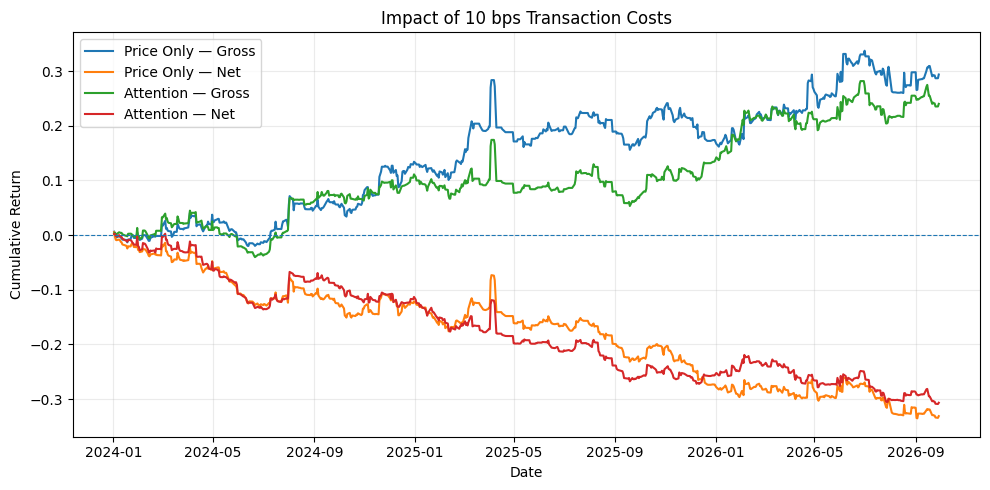

In [82]:
#  Plot gross versus net cumulative performance

price_gross_curve = (
    1 + evaluation_price
).cumprod() - 1

price_net_curve = (
    1 + evaluation_price_net
).cumprod() - 1

attention_gross_curve = (
    1 + evaluation_attention
).cumprod() - 1

attention_net_curve = (
    1 + evaluation_attention_net
).cumprod() - 1

plt.figure(figsize=(10, 5))

plt.plot(
    price_gross_curve.index,
    price_gross_curve,
    label="Price Only — Gross"
)

plt.plot(
    price_net_curve.index,
    price_net_curve,
    label="Price Only — Net"
)

plt.plot(
    attention_gross_curve.index,
    attention_gross_curve,
    label="Attention — Gross"
)

plt.plot(
    attention_net_curve.index,
    attention_net_curve,
    label="Attention — Net"
)

plt.axhline(
    0,
    linewidth=0.8,
    linestyle="--"
)

plt.title(
    "Impact of 10 bps Transaction Costs"
)

plt.xlabel("Date")
plt.ylabel("Cumulative Return")

plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [83]:
#  Final results table (reproduces Table 3.1 in the report)
headline_results = pd.DataFrame({
    "Development: Price-only (gross)": development_metrics(gross_strategy_returns),
    "Development: Attention (gross)": development_metrics(attention_strategy_returns),
    "Development: Price-only (net, 10 bps)": development_metrics(price_net_returns),
    "Development: Attention (net, 10 bps)": development_metrics(attention_net_returns),
    "Later: Price-only (gross)": performance_metrics(evaluation_price),
    "Later: Attention (gross)": performance_metrics(evaluation_attention),
    "Later: Price-only (net, 10 bps)": performance_metrics(evaluation_price_net),
    "Later: Attention (net, 10 bps)": performance_metrics(evaluation_attention_net),
}).T[["Cumulative Return", "Sharpe Ratio", "Maximum Drawdown"]]

display(headline_results.round(4))

,Cumulative Return,Sharpe Ratio,Maximum Drawdown
Development: Price-only (gross),-0.0736,-0.1652,-0.2186
Development: Attention (gross),-0.0808,-0.1943,-0.2600
"Development: Price-only (net, 10 bps)",-0.5265,-2.1129,-0.5437
"Development: Attention (net, 10 bps)",-0.4960,-1.9706,-0.5277
Later: Price-only (gross),0.2940,0.8482,-0.0994
Later: Attention (gross),0.2403,0.8155,-0.1030
"Later: Price-only (net, 10 bps)",-0.3313,-1.1705,-0.3388
"Later: Attention (net, 10 bps)",-0.3068,-1.2480,-0.3108
